In [1]:
TRAIN_CNN = False

<a id="results"></a>
## Results so far

In VS Code, select the **Capstone (.venv)** kernel and run the next cell. **Strict** means whole recordings, bearings, or speeds were held out and is the main test. **Time split** reuses each recording across train and test and is easier; it cannot replace the strict score. A result counts toward the professor's >80% target only if **both strict scores** exceed 80%.

In [1]:
from notebook_helpers import show_overview
show_overview()

,Strict sensor %,Strict visual %,Time sensor %,Time visual %,Status
Equipment,,,,,
Pump,95.83,100.00,NaN,NaN,Both >80%
Haul Truck,80.00,41.67,100.00,91.30,Evaluated
Belt Conveyor,62.50,56.25,100.00,81.25,Evaluated
Excavator,18.75,31.25,93.75,93.75,Evaluated
Dozer,62.50,56.25,100.00,100.00,Evaluated
Wheel Loader,31.25,18.75,93.75,100.00,Evaluated
Drill Rig,NaN,NaN,NaN,NaN,Pending
Grader,NaN,NaN,NaN,NaN,Pending


### Every test image, every machine
Camera CNN, fair test, one image per machine. Each cell counts test images; the images of one recording are near-copies, so the per-recording score above stays the main result.

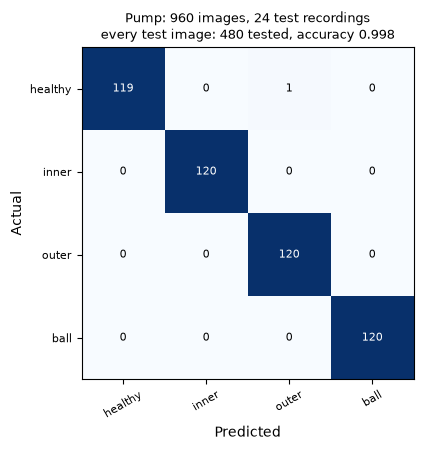

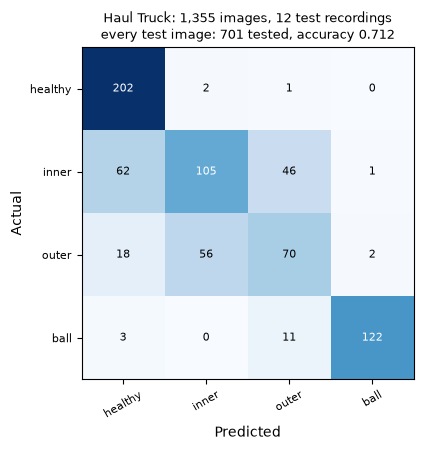

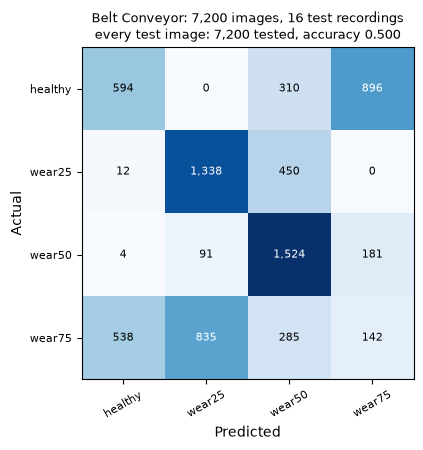

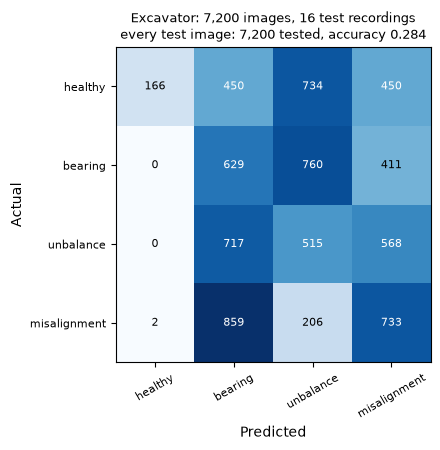

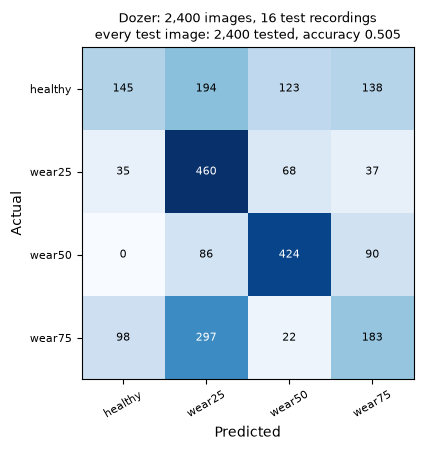

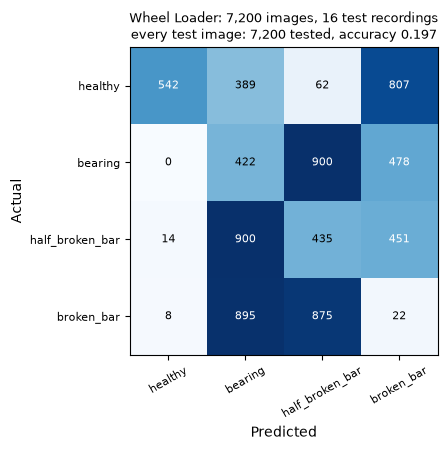

In [1]:
from notebook_helpers import show_test_images
show_test_images()

<a id="controls"></a>
## Run controls

Leave `ACTIVE_EQUIPMENT = None` to inspect saved work without running models. To rerun one section, enter its key below and use **Run All** after its local source files are present. `TRAIN_CNN` controls the optional, slower image training for that selected section.

In [2]:
EQUIPMENT_KEYS = ('pump', 'haul_truck', 'belt_conveyor', 'excavator', 'dozer', 'wheel_loader')
ACTIVE_EQUIPMENT = None  # set to one EQUIPMENT_KEYS value to rerun it
TRAIN_CNN = False       # set True only when retraining the selected equipment's image model
if ACTIVE_EQUIPMENT is not None and ACTIVE_EQUIPMENT not in EQUIPMENT_KEYS:
    raise ValueError(f'Choose one of {EQUIPMENT_KEYS}, or None')
if TRAIN_CNN and ACTIVE_EQUIPMENT is None:
    raise ValueError('Select ACTIVE_EQUIPMENT before enabling TRAIN_CNN')
print('Saved-results mode' if ACTIVE_EQUIPMENT is None else f'Rerunning: {ACTIVE_EQUIPMENT}; CNN: {TRAIN_CNN}')

Saved-results mode


<a id="pump"></a>
# Pump: support bearing — sensor vs camera

| | Sensor | Camera |
|---|---|---|
| Data | University of Ottawa vibration (bearing test rig) | XJTU event camera (lab pump) |
| Classes | healthy, inner race, outer race, ball fault | same four |
| Tested on | 24 recordings never used for training | 24 recordings never used for training |
| Code | `Models/pump.py sensor` | `Models/pump.py camera` |

The two branches use different lab rigs, so they are compared by fault class only. Lab data, not a mining pump; it classifies the present condition, not when to repair.

All of this machine's experiment code is in its `Models/` file; shared notebook set-up is in `notebook_helpers.py`. Run the cells from top to bottom with the **Capstone (.venv)** kernel.

In [3]:
from notebook_helpers import *

LOCAL = setup([
    ("Sensor: Ottawa vibration", "Raw_Data/uottawa_bearing", "*.mat", 48),
    ("Camera: XJTU-DV-Pump zips", "Raw_Data/xjtu_dv_pump", "*.zip", 2),
    ("Extra: original pump XLSX", "Raw_Data/pump_bearing", "*.xlsx", 4),
    ("Extra: UCI hydraulic", "Raw_Data/uci_hydraulic", "*.zip", 1),
    ("Extra: ESPset V3", "Raw_Data/espset_v3", "*.zip", 1),
])

,environment
git commit,c3b6fcb
python,3.11.9
kernel,project .venv
numpy,2.4.6
scipy,1.17.1
pandas,2.3.3
scikit-learn,1.9.1
opencv-python,4.14.0.94
matplotlib,3.11.2


,location,files,MB,local
data,,,,
Sensor: Ottawa vibration,Raw_Data/uottawa_bearing,48/48,631.5,True
Camera: XJTU-DV-Pump zips,Raw_Data/xjtu_dv_pump,2/2,16488.7,True
Extra: original pump XLSX,Raw_Data/pump_bearing,4/4,3.1,True
Extra: UCI hydraulic,Raw_Data/uci_hydraulic,1/1,76.6,True
Extra: ESPset V3,Raw_Data/espset_v3,1/1,0.3,True


All data is local: running fully offline.


In [4]:
run_script, check = select_equipment(ACTIVE_EQUIPMENT, 'pump')

## 1. Sensor: vibration
Train on speed profiles A and B, test on 24 separate C and D recordings (one answer per recording).

In [5]:
before = load("pump_bearing_independent.json")
if LOCAL["Sensor: Ottawa vibration"]:
    run_script("Models/pump.py", "sensor")
sensor = load("pump_bearing_independent.json")
check(before, sensor, [("random_forest_run_level",)], "Sensor")
show({"Sensor model (24 recordings)": sensor["random_forest_run_level"],
      "Always guess one class": sensor["dummy_run_level"]})

Sensor: showing saved results (not rerun).


,accuracy,macro_precision,macro_recall,macro_f1
Sensor model (24 recordings),0.958,0.964,0.958,0.958
Always guess one class,0.250,0.062,0.250,0.100


## 2. Camera: event images with OpenCV
Eight 250 ms event images per recording, OpenCV HOG features. Train on 20 Hz, test on 30 Hz. Extra check: hide each camera set-up in turn.

In [6]:
before = load("pump_event_visual.json")
if LOCAL["Camera: XJTU-DV-Pump zips"]:
    use_local_pump_zips()
    run_script("Models/pump.py", "camera", "--refresh")
camera = load("pump_event_visual.json")
check(before, camera, [("random_forest_run_level",), ("held_out_camera_configuration_run_level",)], "Camera")
show({"Camera model (24 recordings)": camera["random_forest_run_level"],
      "Camera, unseen set-up (48)": camera["held_out_camera_configuration_run_level"],
      "Always guess one class": camera["dummy_run_level"]})

Camera: showing saved results (not rerun).


,accuracy,macro_precision,macro_recall,macro_f1
Camera model (24 recordings),1.000,1.000,1.000,1.000
"Camera, unseen set-up (48)",0.854,0.868,0.854,0.855
Always guess one class,0.250,0.062,0.250,0.100


## 3. Sensor vs camera

In [7]:
run_script("Models/pump.py", "compare", tail=1)
show({"Sensor: vibration": sensor["random_forest_run_level"],
      "Camera: event images": camera["random_forest_run_level"],
      "Camera: unseen set-up": camera["held_out_camera_configuration_run_level"]})

,accuracy,macro_precision,macro_recall,macro_f1
Sensor: vibration,0.958,0.964,0.958,0.958
Camera: event images,1.000,1.000,1.000,1.000
Camera: unseen set-up,0.854,0.868,0.854,0.855


![Pump sensor vs camera](../Figures/pump/pump_sensor_visual_confusions.png)

**What this means:** both work well here (sensor 23/24 = 0.958, camera 24/24 = 1.000; guessing gets 0.250). The camera drops to about 0.85 on an unseen camera set-up. Different rigs, so this is not a winner contest. Full write-up: [`Results/pump/pump_sensor_visual_comparison.md`](../Results/pump/pump_sensor_visual_comparison.md).

## 4. Extra sensor-only pump checks (no camera branch)
UCI hydraulic and ESPset give slightly different numbers under scikit-learn 1.9.1 than the saved ones (a known version issue).

In [8]:
extras = [("Extra: original pump XLSX", "original-xlsx", "pump_bearing_exploratory.json", "random_forest"),
          ("Extra: UCI hydraulic", "uci-hydraulic", "uci_hydraulic_pump_leakage.json", "test_selected"),
          ("Extra: ESPset V3", "espset", "espset_v3_binary_fault.json", "test_selected")]
saved = {name: load(name) for _, _, name, _ in extras}
for key, command, name, part in extras:
    if LOCAL[key]:
        run_script("Models/pump.py", command, tail=1)
show({f"{key} (saved)": saved[name][part] for key, _, name, part in extras} |
     {f"{key} (this run)": load(name)[part] for key, _, name, part in extras})

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
Extra: original pump XLSX (saved),1.000,1.000,1.0,1.0,1.000
Extra: UCI hydraulic (saved),0.962,0.963,NaN,NaN,0.963
Extra: ESPset V3 (saved),0.937,0.904,NaN,NaN,0.914
Extra: original pump XLSX (this run),1.000,1.000,1.0,1.0,1.000
Extra: UCI hydraulic (this run),0.962,0.963,NaN,NaN,0.963
Extra: ESPset V3 (this run),0.937,0.904,NaN,NaN,0.914


## Week 5: baseline model comparison
Four model types are trained with settings fixed in advance and tested on exactly the same held-out recordings as above: a majority-class control, logistic regression, a decision tree and a random forest. No model is picked using these test results; the main model stays the same.

In [9]:
if all(LOCAL[k] for k in ("Sensor: Ottawa vibration", "Camera: XJTU-DV-Pump zips")):
    run_script("Models/pump.py", "baselines", tail=1)
show_baselines(load("pump_baselines.json"))

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
Sensor: vibration | Majority class (control),0.250,0.250,0.062,0.250,0.100
Sensor: vibration | Logistic regression,0.958,0.958,0.964,0.958,0.958
Sensor: vibration | Decision tree,1.000,1.000,1.000,1.000,1.000
Sensor: vibration | Random forest,0.958,0.958,0.964,0.958,0.958
Camera: event camera | Majority class (control),0.250,0.250,0.062,0.250,0.100
Camera: event camera | Logistic regression,1.000,1.000,1.000,1.000,1.000
Camera: event camera | Decision tree,0.875,0.875,0.887,0.875,0.870
Camera: event camera | Random forest,1.000,1.000,1.000,1.000,1.000


![Baseline comparison](../Figures/pump/pump_baselines.png)

## Week 6: professor's remarks (4 classes, CSV sensor model, CNN with augmentation)
- **CSV:** the sensor features are written to `Processed_Data/pump_sensor_features_4class.csv` and 4-class models are trained on it.
- **Named images:** `export-images` saves the camera images as `Images/pump/<class>/pump_<class>_..._tNN.png` (local only).
- **CSV model choice:** the feature set and model are chosen on validation data inside the training set only, then tested once.
- **CNN:** a pretrained ResNet18 (transfer learning) and a small CNN, both with data augmentation (flip, shift, brightness, noise), tested on the same held-out recordings. Retraining takes minutes, so it is off by default; set `TRAIN_CNN = True` to retrain.

In [10]:
if all(LOCAL[k] for k in ("Sensor: Ottawa vibration", "Camera: XJTU-DV-Pump zips")):
    run_script("Models/pump.py", "csv", tail=2)
    if TRAIN_CNN:
        run_script("Models/pump.py", "export-images", tail=1)
        run_script("Models/pump.py", "cnn-pretrained", tail=1)
        run_script("Models/pump.py", "cnn", tail=1)
show_week6("pump")

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
CSV sensor | validation-selected (main),0.958,0.958,0.964,0.958,0.958
CSV sensor | Majority class (control),0.250,0.250,0.062,0.250,0.100
CSV sensor | Logistic regression,0.958,0.958,0.964,0.958,0.958
CSV sensor | Random forest,0.958,0.958,0.964,0.958,0.958
"Camera images | pretrained ResNet18 (main), per recording",1.000,1.000,1.000,1.000,1.000
"Camera images | small CNN, per recording",0.833,0.833,0.900,0.833,0.812


![CSV sensor model](../Figures/pump/pump_csv_4class.png) ![Pretrained CNN](../Figures/pump/pump_cnn_pretrained_4class.png)

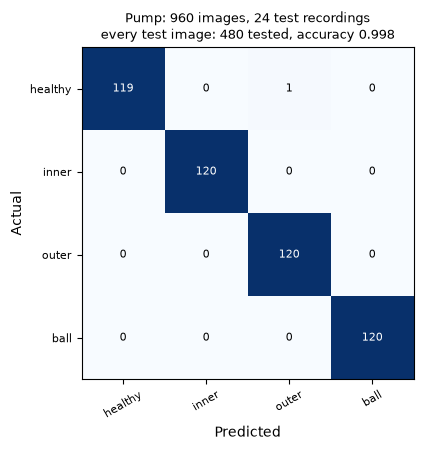

In [2]:
# Every test image of this machine's camera CNN (fair test: the test recordings were never seen in training)
from notebook_helpers import show_test_images
show_test_images("pump")

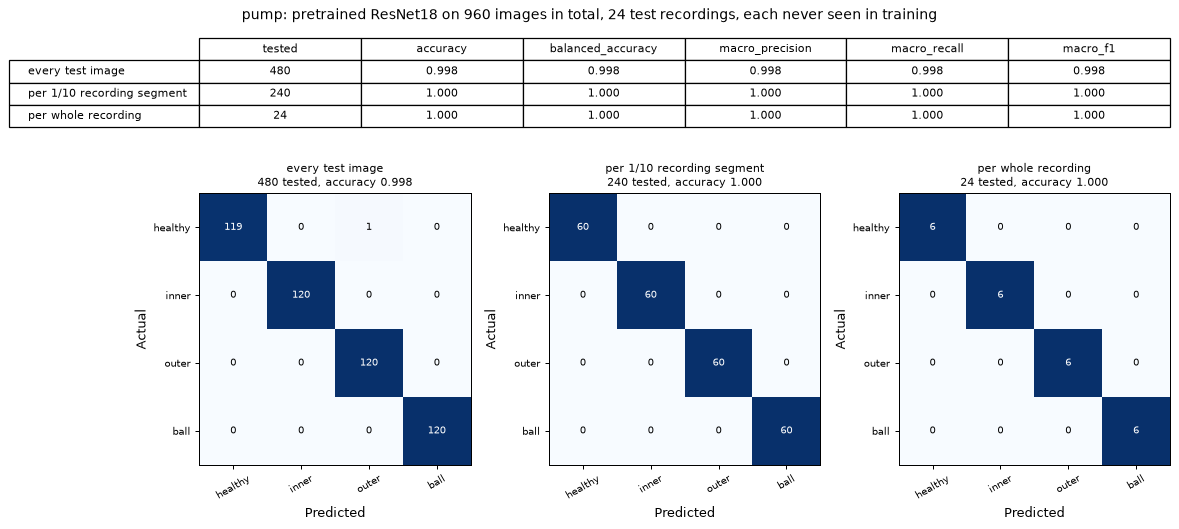

,class,healthy,inner,outer,ball,final answer
30Hz_ball_15_-30,ball,0,0,0,20,ball
30Hz_ball_15_0,ball,0,0,0,20,ball
30Hz_ball_15_30,ball,0,0,0,20,ball
30Hz_ball_18_-30,ball,0,0,0,20,ball
30Hz_ball_18_0,ball,0,0,0,20,ball
30Hz_ball_18_30,ball,0,0,0,20,ball
30Hz_healthy_15_-30,healthy,20,0,0,0,healthy
30Hz_healthy_15_0,healthy,20,0,0,0,healthy
30Hz_healthy_15_30,healthy,20,0,0,0,healthy
30Hz_healthy_18_-30,healthy,20,0,0,0,healthy


In [1]:
# The CNN result at three levels: every test image, every 1/10 recording segment, and every whole recording.
# The figure shows the real number of test images; the last table shows how each recording's images were classified.
from notebook_helpers import show_per_recording
show_per_recording("pump")

## Proposal Week 6: advanced ensemble models (XGBoost / LightGBM)
The same CSV sensor features and the same held-out recordings, now with **XGBoost** and **LightGBM** next to random forest, extra trees and scikit-learn gradient boosting. Settings are fixed in advance; nothing is tuned on the test. `train_seconds` is the total training time.

In [11]:
if all(LOCAL.values()):
    run_script("Models/pump.py", "ensembles", tail=1)
show_ensembles("pump")

,accuracy,balanced_accuracy,macro_f1,train_seconds
MAIN | Majority class (control),0.250,0.250,0.100,0.00
MAIN | Random forest,0.958,0.958,0.958,0.54
MAIN | Extra trees,0.958,0.958,0.958,0.30
MAIN | Gradient boosting (scikit-learn),0.958,0.958,0.958,1.91
MAIN | XGBoost,0.958,0.958,0.958,0.43
MAIN | LightGBM,0.917,0.917,0.916,0.30


![Ensemble comparison](../Figures/pump/pump_ensembles.png)

## Week 7: anomaly detection (trained on healthy data only)
Isolation Forest and One-Class SVM learn only what **healthy** looks like; anything unusual raises an alarm. No fault labels are used for training. The alarm threshold is set from the healthy training recordings before testing. **ROC-AUC** (1.0 = perfect, 0.5 = guessing) shows how well the score separates healthy from faulty; **fault detection rate** and **false alarm rate** are at that fixed threshold.

In [12]:
if all(LOCAL.values()):
    run_script("Models/pump.py", "anomaly", tail=1)
show_anomaly("pump")

,roc_auc,fault_detection_rate,false_alarm_rate,accuracy,test_recordings
MAIN | Isolation Forest,0.9815,1.0,0.1667,0.9583,24.0
MAIN | One-Class SVM,0.9444,1.0,0.1667,0.9583,24.0


![Anomaly scores](../Figures/pump/pump_anomaly.png)

Each dot is one test recording; above the dashed line = alarm. Green = healthy, red = faulty.

## Try your own CSV
Put the path of any CSV in `CSV_FILE` and run this cell. It can be a **feature table** (same columns as `Processed_Data/pump_sensor_features_4class.csv`, optional `class` column) or a **raw recording** (one column of sensor values). Set `LABEL` to the true class to see the accuracy. Classes: healthy, inner, outer, ball. The saved model is trained on all project data, so testing on one of the project's own recordings gives an optimistic score; to test fairly, first run `python Models/pump.py train-final --exclude <recording>`.

In [13]:
CSV_FILE = None   # e.g. r"C:/Users/me/Downloads/my_recording.csv"
LABEL = None      # true class if known
if CSV_FILE:
    run_script("Models/pump.py", "predict", "--csv", CSV_FILE, *((["--label", LABEL] if LABEL else [])), tail=25)
else:
    print("Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).")

Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).


**Data (CC BY 4.0):** University of Ottawa bearing vibration V2, DOI 10.17632/v43hmbwxpm.2; XJTU-DV, DOI 10.5281/zenodo.17447083.

<a id="haul-truck"></a>
# Haul/Dump Truck: wheel-motor bearing — sensor vs camera

| | Sensor | Camera |
|---|---|---|
| Data | UODS vibration (University of Ottawa bearing rig) | XJTU-DV-Rotor event camera (lab rotor rig) |
| Classes | healthy, inner race, outer race | same three |
| Tested on | 20 recordings from bearings never used for training | 9 recordings at an unseen speed |
| Code | `Models/haul_truck.py experiment` (both branches) | |

Ball faults are left out (the sensor data recorded them with no load). Lab rigs, not truck data; compared by fault class only.

All of this machine's experiment code is in its `Models/` file; shared notebook set-up is in `notebook_helpers.py`. Run the cells from top to bottom with the **Capstone (.venv)** kernel.

In [14]:
from notebook_helpers import *

LOCAL = setup([
    ("Sensor: UODS vibration", "Raw_Data/uods_vafdc", "*.mat", 20),
    ("Camera: XJTU-DV-Rotor zip", "Raw_Data/xjtu_dv_rotor", "*.zip", 1),
])

,environment
git commit,c3b6fcb
python,3.11.9
kernel,project .venv
numpy,2.4.6
scipy,1.17.1
pandas,2.3.3
scikit-learn,1.9.1
opencv-python,4.14.0.94
matplotlib,3.11.2


,location,files,MB,local
data,,,,
Sensor: UODS vibration,Raw_Data/uods_vafdc,30/20,106.9,True
Camera: XJTU-DV-Rotor zip,Raw_Data/xjtu_dv_rotor,1/1,2812.1,True


All data is local: running fully offline.


In [15]:
run_script, check = select_equipment(ACTIVE_EQUIPMENT, 'haul_truck')

## Run both branches
**Sensor:** five rounds, each hiding two whole bearings. Inner-race files carry a constant +50 offset (a recording artefact), so each window's mean is removed. **Camera:** train on 1000 rpm, test on 2000 rpm; extra check hides each camera angle.

In [16]:
before = load("haul_truck_wheel_motor_bearing.json")
if all(LOCAL.values()):
    run_script("Models/haul_truck.py", "experiment", "--refresh", tail=1)
truck = load("haul_truck_wheel_motor_bearing.json")
check(before, truck, [("sensor", "held_out_bearings", "model"), ("visual", "train_1000_test_2000_rpm", "model")], "Haul Truck")
show({"Sensor: vibration (20 recordings)": truck["sensor"]["held_out_bearings"]["model"],
      "Camera: event images (9 recordings)": truck["visual"]["train_1000_test_2000_rpm"]["model"],
      "Camera: unseen angle (18)": truck["visual"]["held_out_camera_angle"]["model"],
      "Sensor: always guess one class": truck["sensor"]["held_out_bearings"]["most_frequent_control"],
      "Camera: always guess one class": truck["visual"]["train_1000_test_2000_rpm"]["most_frequent_control"]})

Haul Truck: showing saved results (not rerun).


,accuracy,macro_precision,macro_recall,macro_f1
Sensor: vibration (20 recordings),0.900,0.914,0.867,0.871
Camera: event images (9 recordings),0.444,0.333,0.444,0.356
Camera: unseen angle (18),0.444,0.300,0.444,0.357
Sensor: always guess one class,0.500,0.167,0.333,0.222
Camera: always guess one class,0.333,0.111,0.333,0.167


![Haul Truck sensor vs camera](../Figures/haul_truck/haul_truck_confusions.png)

**What this means:** the sensor works (18/20 = 0.900 on unseen bearings; guessing gets 0.500). The camera does not work well here (4/9 = 0.444, one more than guessing) and never recognises inner-race faults. Different rigs and small test sets. Full write-up: [`Results/haul_truck/haul_truck_sensor_visual_comparison.md`](../Results/haul_truck/haul_truck_sensor_visual_comparison.md).

**Data (CC BY 4.0):** UODS-VAFDC, DOI 10.17632/y2px5tg92h.1; XJTU-DV, DOI 10.5281/zenodo.17447083.

## Week 5: baseline model comparison
Four model types are trained with settings fixed in advance and tested on exactly the same held-out recordings as above: a majority-class control, logistic regression, a decision tree and a random forest. No model is picked using these test results; the main model stays the same.

In [17]:
if all(LOCAL.values()):
    run_script("Models/haul_truck.py", "baselines", tail=1)
show_baselines(load("haul_truck_baselines.json"))

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
Sensor: vibration | Majority class (control),0.500,0.333,0.167,0.333,0.222
Sensor: vibration | Logistic regression,0.850,0.800,0.820,0.800,0.806
Sensor: vibration | Decision tree,0.750,0.700,0.689,0.700,0.691
Sensor: vibration | Random forest,0.900,0.867,0.914,0.867,0.871
Camera: event camera | Majority class (control),0.333,0.333,0.111,0.333,0.167
Camera: event camera | Logistic regression,0.333,0.333,0.278,0.333,0.302
Camera: event camera | Decision tree,0.444,0.444,0.528,0.444,0.473
Camera: event camera | Random forest,0.444,0.444,0.333,0.444,0.356


![Baseline comparison](../Figures/haul_truck/haul_truck_baselines.png)

## Week 6: professor's remarks (4 classes, CSV sensor model, CNN with augmentation)
- **CSV:** the sensor features are written to `Processed_Data/haul_truck_sensor_features_4class.csv` and 4-class models are trained on it.
- **Named images:** `export-images` saves the camera images as `Images/haul_truck/<class>/haul_truck_<class>_..._tNN.png` (local only).
- **CSV model choice:** the feature set and model are chosen on validation data inside the training set only, then tested once.
- **CNN:** a pretrained ResNet18 (transfer learning) and a small CNN, both with data augmentation (flip, shift, brightness, noise), tested on the same held-out recordings. Retraining takes minutes, so it is off by default; set `TRAIN_CNN = True` to retrain.
- **Two tests:** the *main* test holds out whole recordings (or whole speeds/bearings) as before. The *time split* (secondary, easier) trains on the first 60% of every recording and tests on the last 30% (10% gap); the same recordings appear in training, so part of a high score may come from recognising the recording rather than the fault.

In [18]:
if all(LOCAL.values()):
    run_script("Models/haul_truck.py", "csv", tail=2)
    run_script("Models/haul_truck.py", "csv", "--split", "time", tail=1)
    if TRAIN_CNN:
        run_script("Models/haul_truck.py", "export-images", tail=1)
        run_script("Models/haul_truck.py", "cnn-pretrained", tail=1)
        run_script("Models/haul_truck.py", "cnn-pretrained", "--split", "time", tail=1)
        run_script("Models/haul_truck.py", "cnn", tail=1)
show_week6("haul_truck")

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
CSV sensor | validation-selected (main),0.800,0.733,0.760,0.733,0.741
CSV sensor | Majority class (control),0.500,0.250,0.125,0.250,0.167
CSV sensor | Logistic regression,0.767,0.717,0.707,0.717,0.711
CSV sensor | Random forest,0.867,0.833,0.849,0.833,0.831
"Camera images | pretrained ResNet18 (main), per recording",0.417,0.417,0.463,0.417,0.384
"Camera images | small CNN, per recording",0.250,0.250,0.094,0.250,0.136
TIME SPLIT (secondary) | CSV sensor | Random forest,1.000,1.000,1.000,1.000,1.000
TIME SPLIT (secondary) | Camera images | pretrained ResNet18,0.913,0.900,0.929,0.900,0.899


![CSV sensor model](../Figures/haul_truck/haul_truck_csv_4class.png) ![Pretrained CNN](../Figures/haul_truck/haul_truck_cnn_pretrained_4class.png)

Time split (secondary): ![CSV time split](../Figures/haul_truck/haul_truck_csv_4class_timesplit.png) ![CNN time split](../Figures/haul_truck/haul_truck_cnn_pretrained_4class_timesplit.png)

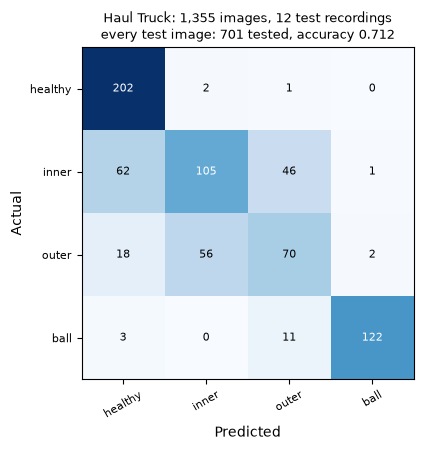

In [3]:
# Every test image of this machine's camera CNN (fair test: the test recordings were never seen in training)
from notebook_helpers import show_test_images
show_test_images("haul_truck")

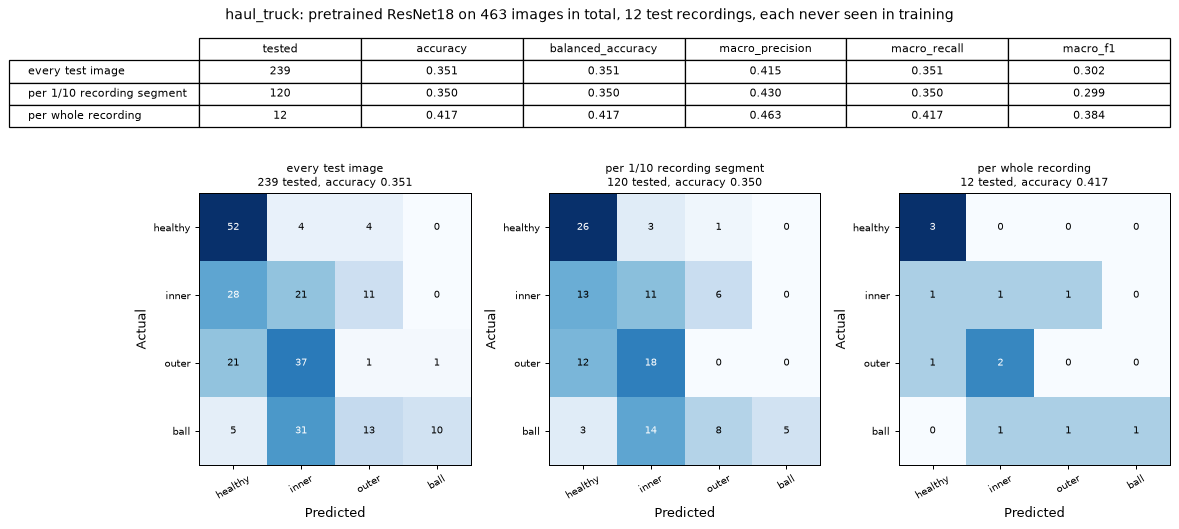

,class,healthy,inner,outer,ball,final answer
2000rpm_ball_angle1,ball,0,20,0,0,inner
2000rpm_ball_angle2,ball,0,7,13,0,outer
2000rpm_ball_angle3,ball,5,4,0,10,ball
2000rpm_healthy_angle1,healthy,16,4,0,0,healthy
2000rpm_healthy_angle2,healthy,16,0,4,0,healthy
2000rpm_healthy_angle3,healthy,20,0,0,0,healthy
2000rpm_inner_angle1,inner,1,19,0,0,inner
2000rpm_inner_angle2,inner,7,2,11,0,outer
2000rpm_inner_angle3,inner,20,0,0,0,healthy
2000rpm_outer_angle1,outer,1,19,0,0,inner


In [2]:
# The CNN result at three levels: every test image, every 1/10 recording segment, and every whole recording.
# The figure shows the real number of test images; the last table shows how each recording's images were classified.
from notebook_helpers import show_per_recording
show_per_recording("haul_truck")

## Proposal Week 6: advanced ensemble models (XGBoost / LightGBM)
The same CSV sensor features and the same held-out recordings, now with **XGBoost** and **LightGBM** next to random forest, extra trees and scikit-learn gradient boosting. Settings are fixed in advance; nothing is tuned on the test. `train_seconds` is the total training time.

In [19]:
if all(LOCAL.values()):
    run_script("Models/haul_truck.py", "ensembles", tail=1)
    run_script("Models/haul_truck.py", "ensembles", "--split", "time", tail=1)
show_ensembles("haul_truck")

,accuracy,balanced_accuracy,macro_f1,train_seconds
MAIN | Majority class (control),0.500,0.250,0.167,0.00
MAIN | Random forest,0.867,0.833,0.831,3.58
MAIN | Extra trees,0.833,0.783,0.780,2.22
MAIN | Gradient boosting (scikit-learn),0.800,0.733,0.734,14.85
MAIN | XGBoost,0.833,0.783,0.775,3.50
MAIN | LightGBM,0.800,0.733,0.733,3.67
TIME SPLIT (secondary) | Majority class (control),0.500,0.250,0.167,0.00
TIME SPLIT (secondary) | Random forest,1.000,1.000,1.000,0.85
TIME SPLIT (secondary) | Extra trees,1.000,1.000,1.000,0.57
TIME SPLIT (secondary) | Gradient boosting (scikit-learn),1.000,1.000,1.000,2.62


![Ensemble comparison](../Figures/haul_truck/haul_truck_ensembles.png)

## Week 7: anomaly detection (trained on healthy data only)
Isolation Forest and One-Class SVM learn only what **healthy** looks like; anything unusual raises an alarm. No fault labels are used for training. The alarm threshold is set from the healthy training recordings before testing. **ROC-AUC** (1.0 = perfect, 0.5 = guessing) shows how well the score separates healthy from faulty; **fault detection rate** and **false alarm rate** are at that fixed threshold.

In [20]:
if all(LOCAL.values()):
    run_script("Models/haul_truck.py", "anomaly", tail=1)
    run_script("Models/haul_truck.py", "anomaly", "--split", "time", tail=1)
show_anomaly("haul_truck")

,roc_auc,fault_detection_rate,false_alarm_rate,accuracy,test_recordings
MAIN | Isolation Forest,0.9600,0.6667,0.0000,0.8333,30.0
MAIN | One-Class SVM,0.9289,0.4000,0.0667,0.6667,30.0
TIME SPLIT (secondary) | Isolation Forest,0.9956,0.6667,0.0000,0.8333,30.0
TIME SPLIT (secondary) | One-Class SVM,1.0000,0.3333,0.0000,0.6667,30.0


![Anomaly scores](../Figures/haul_truck/haul_truck_anomaly.png)

Each dot is one test recording; above the dashed line = alarm. Green = healthy, red = faulty.

## Week 7: every image frame
The same pretrained ResNet18, trained on **every** frame instead of a sample. Results are saved separately (`*_allframes`), so the Week 6 numbers above are unchanged.

In [21]:
if TRAIN_CNN:
    run_script("Models/haul_truck.py", "export-images", "--all-frames", tail=1)
    run_script("Models/haul_truck.py", "cnn-pretrained", "--all-frames", tail=1)
    run_script("Models/haul_truck.py", "cnn-pretrained", "--all-frames", "--split", "time", tail=1)
show_allframes("haul_truck")

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
MAIN | Week 6 frames (463 images),0.417,0.417,0.463,0.417,0.384
TIME SPLIT | Week 6 frames (417 images),0.913,0.900,0.929,0.900,0.899
MAIN | Week 7 all frames (1355 images),0.750,0.750,0.729,0.750,0.731
TIME SPLIT | Week 7 all frames (1225 images),1.000,1.000,1.000,1.000,1.000


![All-frames CNN](../Figures/haul_truck/haul_truck_cnn_pretrained_4class_allframes.png)

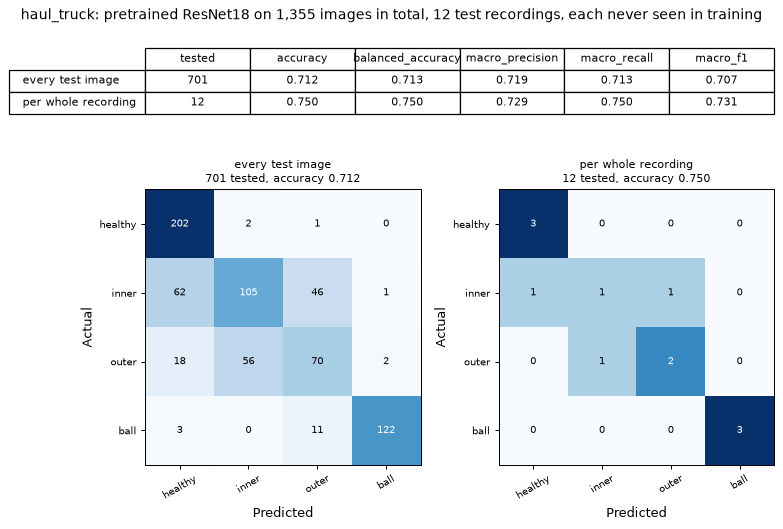

Images per class for each recording appear after rerunning  python Models/haul_truck.py cnn-pretrained


In [3]:
# The CNN result at three levels: every test image, every 1/10 recording segment, and every whole recording.
# The figure shows the real number of test images; the last table shows how each recording's images were classified.
from notebook_helpers import show_per_recording
show_per_recording("haul_truck", "_allframes")

## Try your own CSV
Put the path of any CSV in `CSV_FILE` and run this cell. It can be a **feature table** (same columns as `Processed_Data/haul_truck_sensor_features_4class.csv`, optional `class` column) or a **raw recording** (one column of sensor values). Set `LABEL` to the true class to see the accuracy. Classes: healthy, inner, outer, ball. The saved model is trained on all project data, so testing on one of the project's own recordings gives an optimistic score; to test fairly, first run `python Models/haul_truck.py train-final --exclude <recording>`.

In [22]:
CSV_FILE = None   # e.g. r"C:/Users/me/Downloads/my_recording.csv"
LABEL = None      # true class if known
if CSV_FILE:
    run_script("Models/haul_truck.py", "predict", "--csv", CSV_FILE, *((["--label", LABEL] if LABEL else [])), tail=25)
else:
    print("Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).")

Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).


<a id="belt-conveyor"></a>
# Belt Conveyor: geared drive — sensor vs camera

| | Sensor | Camera |
|---|---|---|
| Data | CORA T1 temperature | CORA infrared camera |
| Classes | healthy vs gear-worn | healthy vs gear-worn |
| Tested on | 16 runs, one speed hidden at a time | the same 16 runs |
| Code | `Models/belt_conveyor.py experiment` (both branches) | |

CORA is one lab motor/gearbox rig, used as a stand-in for a **geared** conveyor drive (not belts or idlers). Both branches use the same runs but are trained separately.

All of this machine's experiment code is in its `Models/` file; shared notebook set-up is in `notebook_helpers.py`. Run the cells from top to bottom with the **Capstone (.venv)** kernel.

In [23]:
from notebook_helpers import *

LOCAL = setup([
    ("Sensor: CORA T1 samples", "Processed_Data/cora_gear_wear/t1_bounded_samples.npz", "*", 1),
    ("Camera: CORA infrared stacks", "Raw_Data/cora_gear_wear", "*.mat", 16),
    ("Sensor: CORA vibration (Vx)", "Raw_Data/cora_vibration", "*_Vx.csv", 16),
])

,environment
git commit,c3b6fcb
python,3.11.9
kernel,project .venv
numpy,2.4.6
scipy,1.17.1
pandas,2.3.3
scikit-learn,1.9.1
opencv-python,4.14.0.94
matplotlib,3.11.2


,location,files,MB,local
data,,,,
Sensor: CORA T1 samples,Processed_Data/cora_gear_wear/t1_bounded_sampl...,1/1,1.7,True
Camera: CORA infrared stacks,Raw_Data/cora_gear_wear,16/16,390.5,True
Sensor: CORA vibration (Vx),Raw_Data/cora_vibration,36/16,3956.3,True


All data is local: running fully offline.


In [24]:
run_script, check = select_equipment(ACTIVE_EQUIPMENT, 'belt_conveyor')

## Run both branches
One script trains the sensor model and the camera model on the same four rounds (each round hides one speed).

In [25]:
before = load("belt_conveyor_cora.json")
if all(LOCAL.values()):
    run_script("Models/belt_conveyor.py", "experiment", tail=1)
belt = load("belt_conveyor_cora.json")
check(before, belt, [("sensor", "model"), ("infrared", "model")], "Belt Conveyor")
show({"Sensor: T1 temperature": belt["sensor"]["model"],
      "Camera: infrared": belt["infrared"]["model"],
      "Always guess 'worn'": belt["sensor"]["most_frequent_control"]})

Belt Conveyor: showing saved results (not rerun).


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
Sensor: T1 temperature,0.625,0.583,0.567,0.583,0.564
Camera: infrared,0.500,0.417,0.433,0.417,0.418
Always guess 'worn',0.750,0.500,0.375,0.500,0.429


![Belt Conveyor sensor vs camera](../Figures/belt_conveyor/belt_conveyor_cora_confusions.png)

**What this means:** weak result, reported honestly. Sensor 0.625 and camera 0.500 are both **below 0.750**, the score from always guessing "worn" (12 of 16 runs are worn). Only 16 runs from one rig. Full write-up: [`Results/belt_conveyor/belt_conveyor_sensor_visual_comparison.md`](../Results/belt_conveyor/belt_conveyor_sensor_visual_comparison.md).

**Data (CC BY 4.0):** CORA v2.1, DOI 10.34810/DATA2500.

## Week 5: baseline model comparison
Four model types are trained with settings fixed in advance and tested on exactly the same held-out recordings as above: a majority-class control, logistic regression, a decision tree and a random forest. No model is picked using these test results; the main model stays the same.

In [26]:
if all(LOCAL.values()):
    run_script("Models/belt_conveyor.py", "baselines", tail=1)
show_baselines(load("belt_conveyor_baselines.json"))

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
Sensor: T1 temperature | Majority class (control),0.750,0.500,0.375,0.500,0.429
Sensor: T1 temperature | Logistic regression,0.625,0.583,0.567,0.583,0.564
Sensor: T1 temperature | Decision tree,0.562,0.458,0.464,0.458,0.459
Sensor: T1 temperature | Random forest,0.625,0.417,0.357,0.417,0.385
Camera: infrared | Majority class (control),0.750,0.500,0.375,0.500,0.429
Camera: infrared | Logistic regression,0.500,0.417,0.433,0.417,0.418
Camera: infrared | Decision tree,0.688,0.625,0.609,0.625,0.614
Camera: infrared | Random forest,0.688,0.542,0.551,0.542,0.543


![Baseline comparison](../Figures/belt_conveyor/belt_conveyor_baselines.png)

## Week 6: professor's remarks (4 classes, CSV sensor model, CNN with augmentation)
- **CSV:** the sensor features are written to `Processed_Data/belt_conveyor_sensor_features_4class.csv` and 4-class models are trained on it.
- **Named images:** `export-images` saves the camera images as `Images/belt_conveyor/<class>/belt_conveyor_<class>_..._tNN.png` (local only).
- **CSV model choice:** the feature set and model are chosen on validation data inside the training set only, then tested once.
- **CNN:** a pretrained ResNet18 (transfer learning) and a small CNN, both with data augmentation (flip, shift, brightness, noise), tested on the same held-out recordings. Retraining takes minutes, so it is off by default; set `TRAIN_CNN = True` to retrain.
- **Two tests:** the *main* test holds out whole recordings (or whole speeds/bearings) as before. The *time split* (secondary, easier) trains on the first 60% of every recording and tests on the last 30% (10% gap); the same recordings appear in training, so part of a high score may come from recognising the recording rather than the fault.

In [27]:
if all(LOCAL.values()):
    run_script("Models/belt_conveyor.py", "csv", tail=2)
    run_script("Models/belt_conveyor.py", "csv", "--split", "time", tail=1)
    if TRAIN_CNN:
        run_script("Models/belt_conveyor.py", "export-images", tail=1)
        run_script("Models/belt_conveyor.py", "cnn-pretrained", tail=1)
        run_script("Models/belt_conveyor.py", "cnn-pretrained", "--split", "time", tail=1)
        run_script("Models/belt_conveyor.py", "cnn", tail=1)
show_week6("belt_conveyor")

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
CSV sensor | validation-selected (main),0.625,0.625,0.625,0.625,0.625
CSV sensor | Majority class (control),0.250,0.250,0.062,0.250,0.100
CSV sensor | Logistic regression,0.375,0.375,0.333,0.375,0.330
CSV sensor | Random forest,0.375,0.375,0.299,0.375,0.288
"Camera images | pretrained ResNet18 (main), per recording",0.562,0.562,0.562,0.562,0.521
"Camera images | small CNN, per recording",0.312,0.312,0.317,0.312,0.205
TIME SPLIT (secondary) | CSV sensor | Random forest,1.000,1.000,1.000,1.000,1.000
TIME SPLIT (secondary) | Camera images | pretrained ResNet18,0.812,0.812,0.893,0.812,0.825


![CSV sensor model](../Figures/belt_conveyor/belt_conveyor_csv_4class.png) ![Pretrained CNN](../Figures/belt_conveyor/belt_conveyor_cnn_pretrained_4class.png)

Time split (secondary): ![CSV time split](../Figures/belt_conveyor/belt_conveyor_csv_4class_timesplit.png) ![CNN time split](../Figures/belt_conveyor/belt_conveyor_cnn_pretrained_4class_timesplit.png)

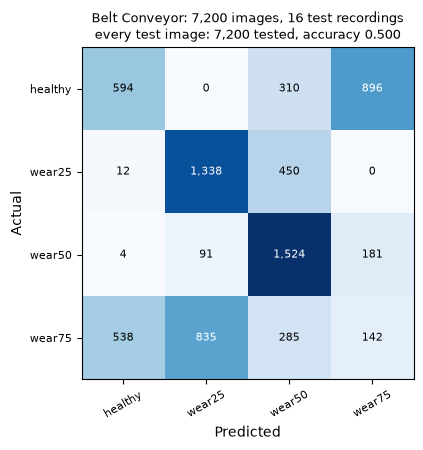

In [4]:
# Every test image of this machine's camera CNN (fair test: the test recordings were never seen in training)
from notebook_helpers import show_test_images
show_test_images("belt_conveyor")

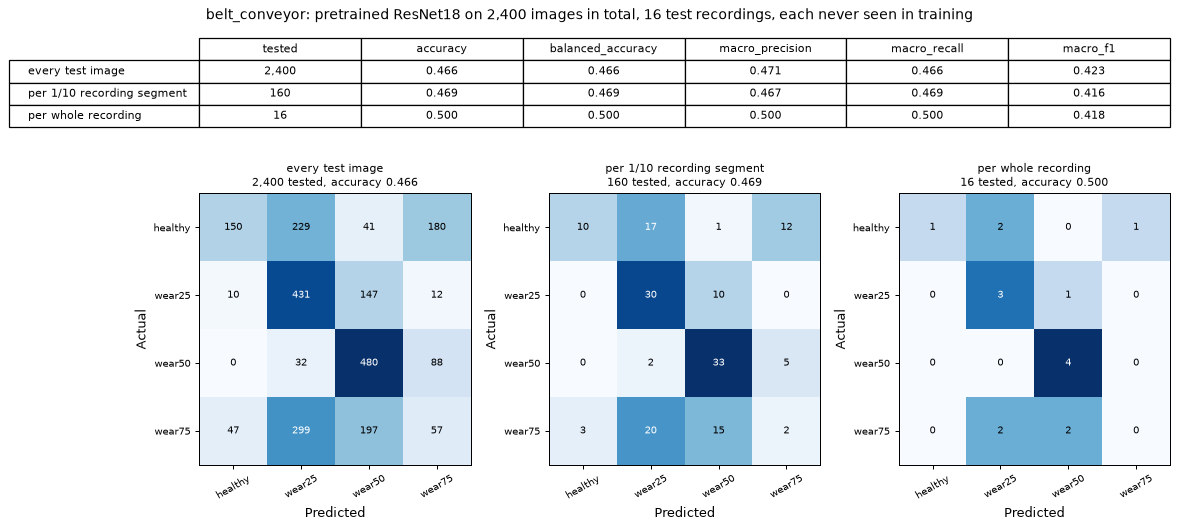

,class,healthy,wear25,wear50,wear75,final answer
H_F5_S,healthy,0,120,30,0,wear25
W25_F5_S,wear25,0,3,147,0,wear50
W50_F5_S,wear50,0,0,150,0,wear50
W75_F5_S,wear75,43,0,94,13,wear50
H_F15_S,healthy,0,106,0,44,wear25
W25_F15_S,wear25,9,141,0,0,wear25
W50_F15_S,wear50,0,0,150,0,wear50
W75_F15_S,wear75,3,0,103,44,wear50
H_F50_S,healthy,0,3,11,136,wear75
W25_F50_S,wear25,1,137,0,12,wear25


In [4]:
# The CNN result at three levels: every test image, every 1/10 recording segment, and every whole recording.
# The figure shows the real number of test images; the last table shows how each recording's images were classified.
from notebook_helpers import show_per_recording
show_per_recording("belt_conveyor")

## Proposal Week 6: advanced ensemble models (XGBoost / LightGBM)
The same CSV sensor features and the same held-out recordings, now with **XGBoost** and **LightGBM** next to random forest, extra trees and scikit-learn gradient boosting. Settings are fixed in advance; nothing is tuned on the test. `train_seconds` is the total training time.

In [28]:
if all(LOCAL.values()):
    run_script("Models/belt_conveyor.py", "ensembles", tail=1)
    run_script("Models/belt_conveyor.py", "ensembles", "--split", "time", tail=1)
show_ensembles("belt_conveyor")

,accuracy,balanced_accuracy,macro_f1,train_seconds
MAIN | Majority class (control),0.250,0.250,0.100,0.00
MAIN | Random forest,0.375,0.375,0.288,4.30
MAIN | Extra trees,0.438,0.438,0.356,2.85
MAIN | Gradient boosting (scikit-learn),0.438,0.438,0.393,54.06
MAIN | XGBoost,0.438,0.438,0.372,10.06
MAIN | LightGBM,0.562,0.562,0.484,14.74
TIME SPLIT (secondary) | Majority class (control),0.250,0.250,0.100,0.00
TIME SPLIT (secondary) | Random forest,1.000,1.000,1.000,1.14
TIME SPLIT (secondary) | Extra trees,1.000,1.000,1.000,0.73
TIME SPLIT (secondary) | Gradient boosting (scikit-learn),1.000,1.000,1.000,13.67


![Ensemble comparison](../Figures/belt_conveyor/belt_conveyor_ensembles.png)

## Week 7: anomaly detection (trained on healthy data only)
Isolation Forest and One-Class SVM learn only what **healthy** looks like; anything unusual raises an alarm. No fault labels are used for training. The alarm threshold is set from the healthy training recordings before testing. **ROC-AUC** (1.0 = perfect, 0.5 = guessing) shows how well the score separates healthy from faulty; **fault detection rate** and **false alarm rate** are at that fixed threshold.

In [29]:
if all(LOCAL.values()):
    run_script("Models/belt_conveyor.py", "anomaly", tail=1)
    run_script("Models/belt_conveyor.py", "anomaly", "--split", "time", tail=1)
show_anomaly("belt_conveyor")

,roc_auc,fault_detection_rate,false_alarm_rate,accuracy,test_recordings
MAIN | Isolation Forest,0.6250,0.0000,0.00,0.2500,16.0
MAIN | One-Class SVM,0.5833,0.3333,0.25,0.4375,16.0
TIME SPLIT (secondary) | Isolation Forest,0.9167,0.0000,0.00,0.2500,16.0
TIME SPLIT (secondary) | One-Class SVM,0.7708,0.5000,0.00,0.6250,16.0


![Anomaly scores](../Figures/belt_conveyor/belt_conveyor_anomaly.png)

Each dot is one test recording; above the dashed line = alarm. Green = healthy, red = faulty.

## Week 7: all available sensor data (every CORA sensor, window and start-up test)
Every 1 s window of vibration X/Y/Z, motor current C1-C3 and temperatures T1-T6, plus the **five start-up tests** per condition and speed, so each held-out speed now has **24 test recordings** (96 in total). Feature set and model are chosen by validation on the training speeds. Temperature identifies the recording session (it separates the conditions already in the first 5 minutes), so temperature sets are shown but never selected. Details: [Week 7 full data](../Documentation/week_07_full_data.md).

In [30]:
run_script("Models/belt_conveyor.py", "fulldata", tail=2)   # runs only when ACTIVE_EQUIPMENT = "belt_conveyor"
show_fulldata("belt_conveyor")

,accuracy (all recordings),test recordings,stationary runs,start-up tests,macro F1
MAIN (unseen speed) | validation-selected,0.5208,96.0,0.6250,0.5000,0.4981
"MAIN | vibration X (as Week 6, all windows) | Random forest",0.4583,96.0,0.5000,0.4500,0.4380
"MAIN | vibration X (as Week 6, all windows) | LightGBM",0.4375,96.0,0.4375,0.4375,0.3988
MAIN | vibration X/Y/Z | Random forest,0.3854,96.0,0.3750,0.3875,0.3799
MAIN | vibration X/Y/Z | LightGBM,0.5417,96.0,0.6250,0.5250,0.5013
MAIN | current C1-C3 | Random forest,0.5208,96.0,0.6250,0.5000,0.5473
MAIN | current C1-C3 | LightGBM,0.5312,96.0,0.5625,0.5250,0.5295
MAIN | vibration + current | Random forest,0.5729,96.0,0.6250,0.5625,0.5812
MAIN | vibration + current | LightGBM,0.5833,96.0,0.6250,0.5750,0.5627
MAIN | vibration + current + temperature pattern (stationary only) | Random forest,0.8750,16.0,0.8750,NaN,0.8611


Validation choices per held-out speed: F5: vibration + current / Random forest; F15: vibration + current / LightGBM; F50: current C1-C3 / Random forest; F60: current C1-C3 / Random forest


![Full-data sensor results](../Figures/belt_conveyor/belt_conveyor_fulldata.png)

### Week 7: XGBoost / LightGBM and anomaly detection on the full data
Same fair main test (each whole speed held out, 96 test recordings), all vibration and current sensors, settings fixed in advance. Anomaly detectors learn healthy data only; the alarm threshold comes from the training speeds.

In [31]:
run_script("Models/belt_conveyor.py", "fulldata", "--part", "ensembles", tail=2)   # runs only when ACTIVE_EQUIPMENT = "belt_conveyor"
run_script("Models/belt_conveyor.py", "fulldata", "--part", "anomaly", tail=2)
show_fulldata_extras("belt_conveyor")

,MAIN accuracy (unseen speed),MAIN macro F1,MAIN stationary,MAIN start-up,TIME SPLIT (secondary),seconds
Majority class (control),0.2500,0.1000,0.2500,0.2500,0.25,0.1
Random forest,0.5729,0.5812,0.6250,0.5625,1.00,3.9
Extra trees,0.5000,0.5051,0.5000,0.5000,1.00,2.5
Gradient boosting (scikit-learn),0.5938,0.5837,0.5625,0.6000,1.00,33.0
XGBoost,0.5312,0.5299,0.4375,0.5500,1.00,5.2
LightGBM,0.5833,0.5627,0.6250,0.5750,1.00,3.4


,roc_auc,fault_detection_rate,false_alarm_rate,test_recordings
MAIN | Isolation Forest,0.6285,0.00,0.00,96.0
TIME SPLIT | Isolation Forest,0.9375,0.00,0.00,16.0
MAIN | One-Class SVM,0.6603,0.25,0.25,96.0
TIME SPLIT | One-Class SVM,0.8333,0.00,0.00,16.0


![Full-data ensembles](../Figures/belt_conveyor/belt_conveyor_fulldata_ensembles.png)
![Full-data anomaly detection](../Figures/belt_conveyor/belt_conveyor_fulldata_anomaly.png)

## Week 7: every image frame
The same pretrained ResNet18, trained on **every** frame instead of a sample. Results are saved separately (`*_allframes`), so the Week 6 numbers above are unchanged.

In [32]:
if TRAIN_CNN:
    run_script("Models/belt_conveyor.py", "export-images", "--all-frames", tail=1)
    run_script("Models/belt_conveyor.py", "cnn-pretrained", "--all-frames", tail=1)
    run_script("Models/belt_conveyor.py", "cnn-pretrained", "--all-frames", "--split", "time", tail=1)
show_allframes("belt_conveyor")

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
MAIN | Week 6 frames (2400 images),0.562,0.562,0.562,0.562,0.521
TIME SPLIT | Week 6 frames (2160 images),0.812,0.812,0.893,0.812,0.825
MAIN | Week 7 all frames (7200 images),0.500,0.500,0.418,0.500,0.432
TIME SPLIT | Week 7 all frames (6480 images),0.938,0.938,0.950,0.938,0.936


![All-frames CNN](../Figures/belt_conveyor/belt_conveyor_cnn_pretrained_4class_allframes.png)

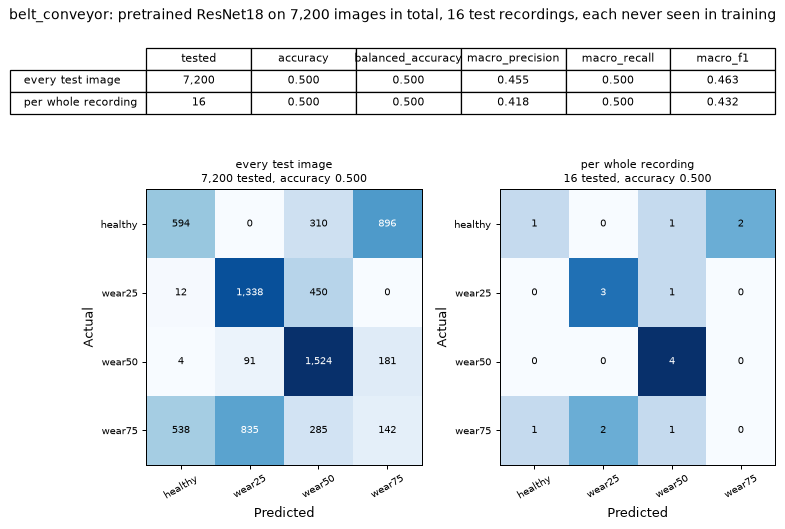

Images per class for each recording appear after rerunning  python Models/belt_conveyor.py cnn-pretrained


In [5]:
# The CNN result at three levels: every test image, every 1/10 recording segment, and every whole recording.
# The figure shows the real number of test images; the last table shows how each recording's images were classified.
from notebook_helpers import show_per_recording
show_per_recording("belt_conveyor", "_allframes")

## Try your own CSV
Put the path of any CSV in `CSV_FILE` and run this cell. It can be a **feature table** (same columns as `Processed_Data/belt_conveyor_sensor_features_4class.csv`, optional `class` column) or a **raw recording** (one column of sensor values). Set `LABEL` to the true class to see the accuracy. Classes: healthy, wear25, wear50, wear75. The saved model is trained on all project data, so testing on one of the project's own recordings gives an optimistic score; to test fairly, first run `python Models/belt_conveyor.py train-final --exclude <recording>`.

In [33]:
CSV_FILE = None   # e.g. r"C:/Users/me/Downloads/my_recording.csv"
LABEL = None      # true class if known
SPEED = None      # raw recordings only: "F5", "F15", "F50" or "F60"
if CSV_FILE:
    run_script("Models/belt_conveyor.py", "predict", "--csv", CSV_FILE, *((["--label", LABEL] if LABEL else []) + (["--speed", SPEED] if SPEED else [])), tail=25)
else:
    print("Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).")

Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).


<a id="excavator"></a>
# Excavator (machine 4): swing-drive motor and gearbox — sensor vs camera

| | Sensor | Camera |
|---|---|---|
| Data | CORA vibration (Vx, 3 kHz) | CORA infrared camera |
| Classes | healthy, bearing defect, unbalance, misalignment | same four |
| Tested on | 16 runs, one speed held out at a time | the same 16 runs |
| Code | `Models/excavator.py csv` | `Models/excavator.py cnn-pretrained` |

Same CORA laboratory motor/gearbox rig as the Belt Conveyor, but a **different task**: drive-train faults (bearing defect, unbalance, misalignment) instead of gear wear. Lab data, not an excavator; it classifies the present condition, not when to repair.

All of this machine's experiment code is in its `Models/` file; shared notebook set-up is in `notebook_helpers.py`. Run the cells from top to bottom with the **Capstone (.venv)** kernel.

In [34]:
from notebook_helpers import *

LOCAL = setup([
    ("Sensor: CORA vibration (16 runs)", "Raw_Data/cora_vibration", "*_Vx.csv", 16),
    ("Camera: CORA infrared, faults", "Raw_Data/cora_drive_faults", "*.mat", 12),
    ("Camera: CORA infrared, healthy", "Raw_Data/cora_gear_wear", "H_*.mat", 4),
])

,environment
git commit,c3b6fcb
python,3.11.9
kernel,project .venv
numpy,2.4.6
scipy,1.17.1
pandas,2.3.3
scikit-learn,1.9.1
opencv-python,4.14.0.94
matplotlib,3.11.2


,location,files,MB,local
data,,,,
Sensor: CORA vibration (16 runs),Raw_Data/cora_vibration,36/16,3956.3,True
"Camera: CORA infrared, faults",Raw_Data/cora_drive_faults,20/12,451.3,True
"Camera: CORA infrared, healthy",Raw_Data/cora_gear_wear,4/4,118.2,True


All data is local: running fully offline.


In [35]:
run_script, check = select_equipment(ACTIVE_EQUIPMENT, 'excavator')

## 1. Sensor: vibration (CSV)
Each run's vibration becomes 1-second windows measured in **shaft orders** (multiples of the shaft speed): unbalance shows at 1x, misalignment at 2x, bearing defects at higher orders and spikes. The features go into a CSV table; the model and feature set are chosen on validation speeds inside the training data, then tested once on the held-out speed.

In [36]:
if all(LOCAL.values()):
    run_script("Models/excavator.py", "csv", tail=2)                    # main: unseen speed
    run_script("Models/excavator.py", "csv", "--split", "time", tail=1)  # secondary: time split
csv_result, time_result = load("excavator_csv_4class.json"), load("excavator_csv_4class_timesplit.json")
show({"MAIN (unseen speed) | Sensor: validation-selected": csv_result["validation_selected"]["score"],
      **{f"MAIN (unseen speed) | Sensor: {k}": v for k, v in csv_result["models"].items()},
      **{f"TIME SPLIT | Sensor: {k}": v for k, v in time_result["models"].items()}})

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
MAIN (unseen speed) | Sensor: validation-selected,0.188,0.188,0.098,0.188,0.129
MAIN (unseen speed) | Sensor: Majority class (control),0.250,0.250,0.062,0.250,0.100
MAIN (unseen speed) | Sensor: Logistic regression,0.188,0.188,0.075,0.188,0.107
MAIN (unseen speed) | Sensor: Random forest,0.188,0.188,0.121,0.188,0.146
TIME SPLIT | Sensor: Majority class (control),0.250,0.250,0.062,0.250,0.100
TIME SPLIT | Sensor: Logistic regression,0.812,0.812,0.825,0.812,0.811
TIME SPLIT | Sensor: Random forest,0.938,0.938,0.950,0.938,0.936


![CSV sensor model](../Figures/excavator/excavator_csv_4class.png) ![Time split](../Figures/excavator/excavator_csv_4class_timesplit.png)

**Two tests, clearly separated.** *Main (unseen speed):* each whole speed is held out, so the model must recognise a fault at a speed it never trained on; CORA has only one run per fault per speed, and every model stays near chance. *Time split (secondary, easier):* the first 60% of every 45-minute run trains, the last 30% tests (10% gap). This asks whether the condition of a machine already seen can be recognised later in time. Because each fault comes from a single recording, part of a high time-split score may come from recognising the recording rather than the fault.

## 2. Camera: infrared images with a pretrained CNN
`export-images` saves 150 infrared frames per run as `Images/excavator/<class>/excavator_<class>_<speed>_fNNN.png`. A pretrained ResNet18 is fine-tuned with data augmentation; the number of training rounds is chosen on validation runs. Retraining takes several minutes, so it is off by default.

In [37]:
if TRAIN_CNN and all(LOCAL.values()):
    run_script("Models/excavator.py", "export-images", tail=1)
    run_script("Models/excavator.py", "cnn-pretrained", tail=1)
    run_script("Models/excavator.py", "cnn-pretrained", "--split", "time", tail=1)
    run_script("Models/excavator.py", "cnn", tail=1)
rows = {}
for name, label in (("excavator_cnn_pretrained_4class.json", "MAIN (unseen speed) | Camera: pretrained ResNet18"),
                    ("excavator_cnn_4class.json", "MAIN (unseen speed) | Camera: small CNN"),
                    ("excavator_cnn_pretrained_4class_timesplit.json", "TIME SPLIT | Camera: pretrained ResNet18")):
    r = load(name)
    if r:
        rows[f"{label} (per run)"] = r["recording_level"]
show(rows)

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
MAIN (unseen speed) | Camera: pretrained ResNet18 (per run),0.312,0.312,0.220,0.312,0.254
MAIN (unseen speed) | Camera: small CNN (per run),0.312,0.312,0.271,0.312,0.267
TIME SPLIT | Camera: pretrained ResNet18 (per run),0.938,0.938,0.950,0.938,0.936


![Pretrained CNN](../Figures/excavator/excavator_cnn_pretrained_4class.png) ![Time split](../Figures/excavator/excavator_cnn_pretrained_4class_timesplit.png)

**Data (CC BY 4.0):** CORA v2.1, DOI 10.34810/DATA2500 (downloaded in a browser because the repository shows a bot check; every file checked against the publisher MD5 by `python Models/excavator.py intake`).

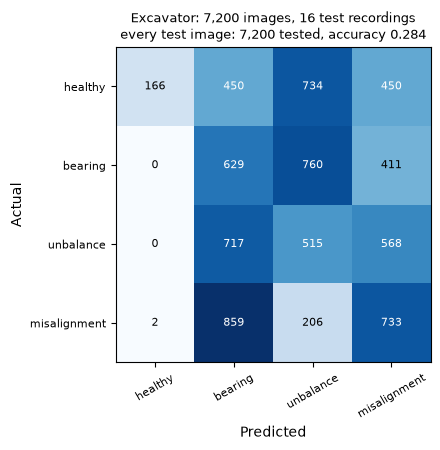

In [5]:
# Every test image of this machine's camera CNN (fair test: the test recordings were never seen in training)
from notebook_helpers import show_test_images
show_test_images("excavator")

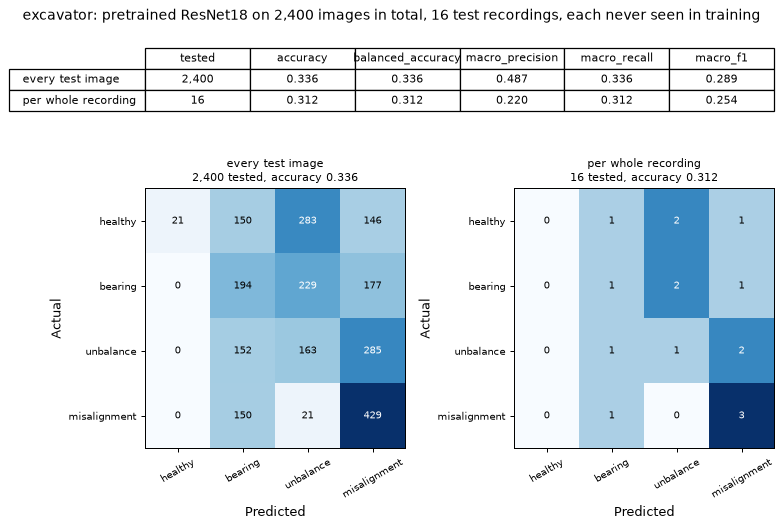

Images per class for each recording appear after rerunning  python Models/excavator.py cnn-pretrained


In [6]:
# The CNN result at three levels: every test image, every 1/10 recording segment, and every whole recording.
# The figure shows the real number of test images; the last table shows how each recording's images were classified.
from notebook_helpers import show_per_recording
show_per_recording("excavator")

## Proposal Week 6: advanced ensemble models (XGBoost / LightGBM)
The same CSV sensor features and the same held-out recordings, now with **XGBoost** and **LightGBM** next to random forest, extra trees and scikit-learn gradient boosting. Settings are fixed in advance; nothing is tuned on the test. `train_seconds` is the total training time.

In [38]:
if all(LOCAL.values()):
    run_script("Models/excavator.py", "ensembles", tail=1)
    run_script("Models/excavator.py", "ensembles", "--split", "time", tail=1)
show_ensembles("excavator")

,accuracy,balanced_accuracy,macro_f1,train_seconds
MAIN | Majority class (control),0.250,0.250,0.100,0.00
MAIN | Random forest,0.250,0.250,0.209,4.52
MAIN | Extra trees,0.312,0.312,0.265,2.70
MAIN | Gradient boosting (scikit-learn),0.250,0.250,0.218,45.30
MAIN | XGBoost,0.250,0.250,0.212,10.98
MAIN | LightGBM,0.312,0.312,0.265,13.67
TIME SPLIT (secondary) | Majority class (control),0.250,0.250,0.100,0.00
TIME SPLIT (secondary) | Random forest,0.938,0.938,0.936,1.20
TIME SPLIT (secondary) | Extra trees,0.938,0.938,0.936,0.74
TIME SPLIT (secondary) | Gradient boosting (scikit-learn),0.938,0.938,0.936,7.33


![Ensemble comparison](../Figures/excavator/excavator_ensembles.png)

## Week 7: anomaly detection (trained on healthy data only)
Isolation Forest and One-Class SVM learn only what **healthy** looks like; anything unusual raises an alarm. No fault labels are used for training. The alarm threshold is set from the healthy training recordings before testing. **ROC-AUC** (1.0 = perfect, 0.5 = guessing) shows how well the score separates healthy from faulty; **fault detection rate** and **false alarm rate** are at that fixed threshold.

In [39]:
if all(LOCAL.values()):
    run_script("Models/excavator.py", "anomaly", tail=1)
    run_script("Models/excavator.py", "anomaly", "--split", "time", tail=1)
show_anomaly("excavator")

,roc_auc,fault_detection_rate,false_alarm_rate,accuracy,test_recordings
MAIN | Isolation Forest,0.4167,0.0000,0.00,0.2500,16.0
MAIN | One-Class SVM,0.5000,0.1667,0.25,0.3125,16.0
TIME SPLIT (secondary) | Isolation Forest,0.8750,0.0000,0.00,0.2500,16.0
TIME SPLIT (secondary) | One-Class SVM,0.7292,0.1667,0.00,0.3750,16.0


![Anomaly scores](../Figures/excavator/excavator_anomaly.png)

Each dot is one test recording; above the dashed line = alarm. Green = healthy, red = faulty.

## Week 7: all available sensor data (every CORA sensor, window and start-up test)
Every 1 s window of vibration X/Y/Z, motor current C1-C3 and temperatures T1-T6, plus the **five start-up tests** per condition and speed, so each held-out speed now has **24 test recordings** (96 in total). Feature set and model are chosen by validation on the training speeds. Temperature identifies the recording session (it separates the conditions already in the first 5 minutes), so temperature sets are shown but never selected. Details: [Week 7 full data](../Documentation/week_07_full_data.md).

In [40]:
run_script("Models/excavator.py", "fulldata", tail=2)   # runs only when ACTIVE_EQUIPMENT = "excavator"
show_fulldata("excavator")

,accuracy (all recordings),test recordings,stationary runs,start-up tests,macro F1
MAIN (unseen speed) | validation-selected,0.3750,96.0,0.4375,0.3625,0.3305
"MAIN | vibration X (as Week 6, all windows) | Random forest",0.3854,96.0,0.4375,0.3750,0.3225
"MAIN | vibration X (as Week 6, all windows) | LightGBM",0.3125,96.0,0.3125,0.3125,0.2618
MAIN | vibration X/Y/Z | Random forest,0.3854,96.0,0.4375,0.3750,0.3671
MAIN | vibration X/Y/Z | LightGBM,0.3854,96.0,0.4375,0.3750,0.3917
MAIN | current C1-C3 | Random forest,0.4688,96.0,0.4375,0.4750,0.4094
MAIN | current C1-C3 | LightGBM,0.4896,96.0,0.5000,0.4875,0.4818
MAIN | vibration + current | Random forest,0.4375,96.0,0.4375,0.4375,0.4283
MAIN | vibration + current | LightGBM,0.4375,96.0,0.5000,0.4250,0.3731
MAIN | vibration + current + temperature pattern (stationary only) | Random forest,0.8750,16.0,0.8750,NaN,0.8750


Validation choices per held-out speed: F5: current C1-C3 / LightGBM; F15: vibration X (as Week 6, all windows) / LightGBM; F50: current C1-C3 / Random forest; F60: vibration + current / LightGBM


![Full-data sensor results](../Figures/excavator/excavator_fulldata.png)

### Week 7: XGBoost / LightGBM and anomaly detection on the full data
Same fair main test (each whole speed held out, 96 test recordings), all vibration and current sensors, settings fixed in advance. Anomaly detectors learn healthy data only; the alarm threshold comes from the training speeds.

In [41]:
run_script("Models/excavator.py", "fulldata", "--part", "ensembles", tail=2)   # runs only when ACTIVE_EQUIPMENT = "excavator"
run_script("Models/excavator.py", "fulldata", "--part", "anomaly", tail=2)
show_fulldata_extras("excavator")

,MAIN accuracy (unseen speed),MAIN macro F1,MAIN stationary,MAIN start-up,TIME SPLIT (secondary),seconds
Majority class (control),0.2500,0.1000,0.2500,0.2500,0.25,0.3
Random forest,0.4375,0.4283,0.4375,0.4375,1.00,4.6
Extra trees,0.4583,0.4368,0.4375,0.4625,1.00,3.1
Gradient boosting (scikit-learn),0.4167,0.3700,0.4375,0.4125,1.00,37.0
XGBoost,0.4583,0.4157,0.4375,0.4625,1.00,6.0
LightGBM,0.4271,0.3662,0.5000,0.4125,1.00,4.5


,roc_auc,fault_detection_rate,false_alarm_rate,test_recordings
MAIN | Isolation Forest,0.5579,0.00,0.00,96.0
TIME SPLIT | Isolation Forest,0.8333,0.00,0.00,16.0
MAIN | One-Class SVM,0.6505,0.25,0.25,96.0
TIME SPLIT | One-Class SVM,0.7292,0.00,0.00,16.0


![Full-data ensembles](../Figures/excavator/excavator_fulldata_ensembles.png)
![Full-data anomaly detection](../Figures/excavator/excavator_fulldata_anomaly.png)

## Week 7: every image frame
The same pretrained ResNet18, trained on **every** frame instead of a sample. Results are saved separately (`*_allframes`), so the Week 6 numbers above are unchanged.

In [42]:
if TRAIN_CNN:
    run_script("Models/excavator.py", "export-images", "--all-frames", tail=1)
    run_script("Models/excavator.py", "cnn-pretrained", "--all-frames", tail=1)
    run_script("Models/excavator.py", "cnn-pretrained", "--all-frames", "--split", "time", tail=1)
show_allframes("excavator")

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
MAIN | Week 6 frames (2400 images),0.312,0.312,0.220,0.312,0.254
TIME SPLIT | Week 6 frames (2160 images),0.938,0.938,0.950,0.938,0.936
MAIN | Week 7 all frames (7200 images),0.250,0.250,0.192,0.250,0.217
TIME SPLIT | Week 7 all frames (6480 images),1.000,1.000,1.000,1.000,1.000


![All-frames CNN](../Figures/excavator/excavator_cnn_pretrained_4class_allframes.png)

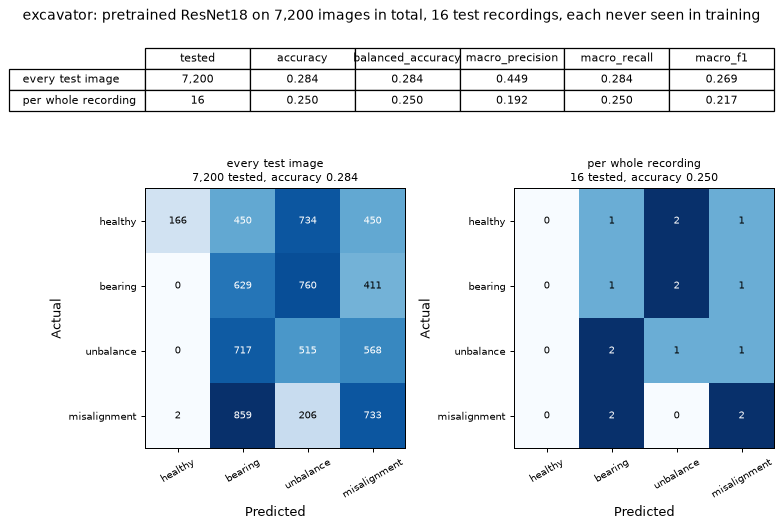

Images per class for each recording appear after rerunning  python Models/excavator.py cnn-pretrained


In [7]:
# The CNN result at three levels: every test image, every 1/10 recording segment, and every whole recording.
# The figure shows the real number of test images; the last table shows how each recording's images were classified.
from notebook_helpers import show_per_recording
show_per_recording("excavator", "_allframes")

## Separate image data for the Excavator (Week 8)
The professor asked for separate data for each machine instead of reusing the CORA rig. This test uses a different, independent dataset: **induction-motor thermal images** (Kulkarni et al., Mendeley Data pymtdhfzbj v2, CC BY 4.0), **healthy vs corroded bearing**, each filmed at no, medium and full load (6 sessions, 488 images).

- **Fair test:** one load is held out in turn, so the model is tested on a load it never saw. Epochs are chosen on the training loads only.
- The burned-in temperature reading and logo (top 15% of each image) are masked.
- **Brightness-only control:** if a model using only overall image brightness scores as well, the CNN is just reading temperature, not the bearing fault.
- Only 2 of the Excavator's 4 classes are covered, and there are only 6 sessions, so this is a check, not a final result.

,tested,accuracy,balanced_accuracy,macro_f1
every test image,488,1.000,1.00,1.000
per 1/10 session segment,60,1.000,1.00,1.000
per whole session,6,1.000,1.00,1.000
control: brightness only (per image),488,0.623,0.57,0.543
"control: border only, motor hidden (per image)",488,0.717,0.68,0.681


,epochs_chosen,test_images,image_accuracy,brightness_control_accuracy,border_only_control_accuracy
test_load,,,,,
no load,1,166,1.0,0.5422,0.5422
medium load,8,161,1.0,0.5093,0.7826
full load,1,161,1.0,0.8199,0.8323


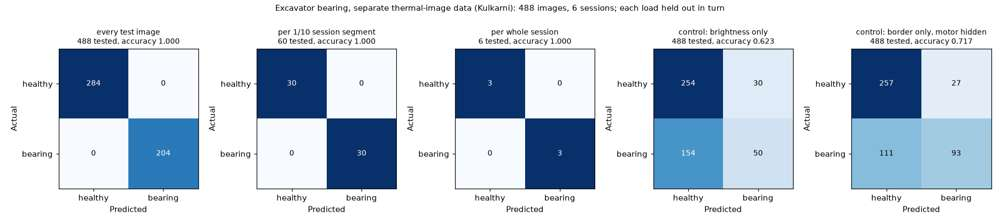

Caveat: only 6 sessions (one per class and load) from one motor; images within a session are consecutive and related, and only 2 classes match the Excavator's 4. The healthy and corroded sessions were filmed with different framing: a model that sees only the image border (motor hidden) also scores well, so a high CNN score does not prove it detects bearing corrosion


In [2]:
if TRAIN_CNN:
    run_script("Models/excavator.py", "thermal-motor", tail=2)
from notebook_helpers import show_thermal_motor
show_thermal_motor()

## Try your own CSV
Put the path of any CSV in `CSV_FILE` and run this cell. It can be a **feature table** (same columns as `Processed_Data/excavator_sensor_features_4class.csv`, optional `class` column) or a **raw recording** (one column of sensor values). Set `LABEL` to the true class to see the accuracy. Classes: healthy, bearing, unbalance, misalignment. The saved model is trained on all project data, so testing on one of the project's own recordings gives an optimistic score; to test fairly, first run `python Models/excavator.py train-final --exclude <recording>`.

In [43]:
CSV_FILE = None   # e.g. r"C:/Users/me/Downloads/my_recording.csv"
LABEL = None      # true class if known
SPEED = None      # raw recordings only: "F5", "F15", "F50" or "F60"
if CSV_FILE:
    run_script("Models/excavator.py", "predict", "--csv", CSV_FILE, *((["--label", LABEL] if LABEL else []) + (["--speed", SPEED] if SPEED else [])), tail=25)
else:
    print("Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).")

Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).


<a id="dozer"></a>
# Dozer (machine 5): track final-drive gear wear — sensor vs camera

| | Sensor | Camera |
|---|---|---|
| Data | CORA vibration (Vx, 3 kHz) + T1 temperature | CORA infrared camera |
| Classes | healthy, wear 25%, wear 50%, wear 75% | same four |
| Tested on | 16 runs, one speed held out at a time | the same 16 runs |
| Code | `Models/dozer.py csv` | `Models/dozer.py cnn-pretrained` |

**Important:** there is no public dozer dataset with matching sensor and camera data. As planned in the dataset manifest, the Dozer final drive uses the **same 16 CORA gear-wear runs as the Belt Conveyor (not new data)** with the **same 4 wear classes**, so its scores are expected to **equal the Belt Conveyor's**: it maps that rig to the dozer track final drive and is not separate evidence. Lab data, not a dozer; it classifies the present condition, not when to repair.

All of this machine's experiment code is in `Models/dozer.py` (data loading shared with `Models/belt_conveyor.py`); shared notebook set-up is in `notebook_helpers.py`. Run the cells from top to bottom with the **Capstone (.venv)** kernel.

In [44]:
from notebook_helpers import *

LOCAL = setup([
    ("Sensor: CORA T1 samples", "Processed_Data/cora_gear_wear/t1_bounded_samples.npz", "*", 1),
    ("Sensor: CORA vibration (Vx)", "Raw_Data/cora_vibration", "*_Vx.csv", 16),
    ("Camera: CORA infrared stacks", "Raw_Data/cora_gear_wear", "*.mat", 16),
])

,environment
git commit,c3b6fcb
python,3.11.9
kernel,project .venv
numpy,2.4.6
scipy,1.17.1
pandas,2.3.3
scikit-learn,1.9.1
opencv-python,4.14.0.94
matplotlib,3.11.2


,location,files,MB,local
data,,,,
Sensor: CORA T1 samples,Processed_Data/cora_gear_wear/t1_bounded_sampl...,1/1,1.7,True
Sensor: CORA vibration (Vx),Raw_Data/cora_vibration,36/16,3956.3,True
Camera: CORA infrared stacks,Raw_Data/cora_gear_wear,16/16,390.5,True


All data is local: running fully offline.


In [45]:
run_script, check = select_equipment(ACTIVE_EQUIPMENT, 'dozer')

## 1. Sensor: vibration and temperature (CSV)
Each run's vibration becomes 1-second windows measured in **shaft orders** (multiples of the shaft speed), optionally with the run's T1 temperature. Gear-tooth wear shows at higher orders and in spikes. The features go into a CSV table; the model and feature set are chosen on validation speeds inside the training data, then tested once on the held-out speed.

In [46]:
if all(LOCAL.values()):
    run_script("Models/dozer.py", "csv", tail=2)                    # main: unseen speed
    run_script("Models/dozer.py", "csv", "--split", "time", tail=1)  # secondary: time split
csv_result, time_result = load("dozer_csv_4class.json"), load("dozer_csv_4class_timesplit.json")
show({"MAIN (unseen speed) | Sensor: validation-selected": csv_result["validation_selected"]["score"],
      **{f"MAIN (unseen speed) | Sensor: {k}": v for k, v in csv_result["models"].items()},
      **{f"TIME SPLIT | Sensor: {k}": v for k, v in time_result["models"].items()}})

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
MAIN (unseen speed) | Sensor: validation-selected,0.625,0.625,0.625,0.625,0.625
MAIN (unseen speed) | Sensor: Majority class (control),0.250,0.250,0.062,0.250,0.100
MAIN (unseen speed) | Sensor: Logistic regression,0.375,0.375,0.333,0.375,0.330
MAIN (unseen speed) | Sensor: Random forest,0.375,0.375,0.299,0.375,0.288
TIME SPLIT | Sensor: Majority class (control),0.250,0.250,0.062,0.250,0.100
TIME SPLIT | Sensor: Logistic regression,0.875,0.875,0.917,0.875,0.879
TIME SPLIT | Sensor: Random forest,1.000,1.000,1.000,1.000,1.000


![CSV sensor model](../Figures/dozer/dozer_csv_4class.png) ![Time split](../Figures/dozer/dozer_csv_4class_timesplit.png)

**Two tests, clearly separated.** *Main (unseen speed):* each whole speed is held out (4 runs, one per wear level), so the model must recognise the wear level at a speed it never trained on. *Time split (secondary, easier):* the first 60% of every 50-minute run trains, the last 30% tests (10% gap); the same recordings appear in training, so part of a high score may come from recognising the recording rather than the wear.

## 2. Camera: infrared images with a pretrained CNN
`export-images` saves 150 infrared frames per run as `Images/dozer/<class>/dozer_<class>_<speed>_fNNN.png`. A pretrained ResNet18 is fine-tuned with data augmentation; the number of training rounds is chosen on validation runs. Retraining takes about half an hour, so it is off by default.

In [47]:
if TRAIN_CNN and all(LOCAL.values()):
    run_script("Models/dozer.py", "export-images", tail=1)
    run_script("Models/dozer.py", "cnn-pretrained", tail=1)
    run_script("Models/dozer.py", "cnn-pretrained", "--split", "time", tail=1)
rows = {}
for name, label in (("dozer_cnn_pretrained_4class.json", "MAIN (unseen speed) | Camera: pretrained ResNet18"),
                    ("dozer_cnn_pretrained_4class_timesplit.json", "TIME SPLIT | Camera: pretrained ResNet18")):
    r = load(name)
    if r:
        rows[f"{label} (per run)"] = r["recording_level"]
show(rows)

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
MAIN (unseen speed) | Camera: pretrained ResNet18 (per run),0.562,0.562,0.562,0.562,0.521
TIME SPLIT | Camera: pretrained ResNet18 (per run),1.000,1.000,1.000,1.000,1.000


![Pretrained CNN](../Figures/dozer/dozer_cnn_pretrained_4class.png) ![Time split](../Figures/dozer/dozer_cnn_pretrained_4class_timesplit.png)

**Data (CC BY 4.0):** CORA v2.1, DOI 10.34810/DATA2500, the same files as the Belt Conveyor.

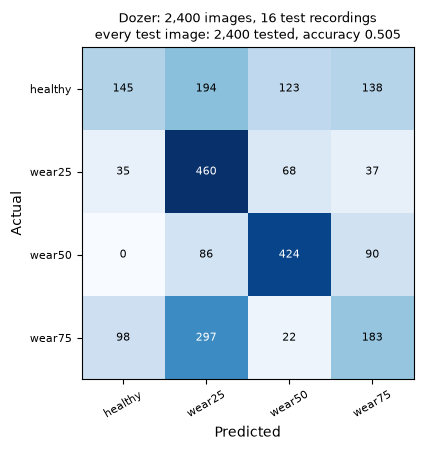

In [6]:
# Every test image of this machine's camera CNN (fair test: the test recordings were never seen in training)
from notebook_helpers import show_test_images
show_test_images("dozer")

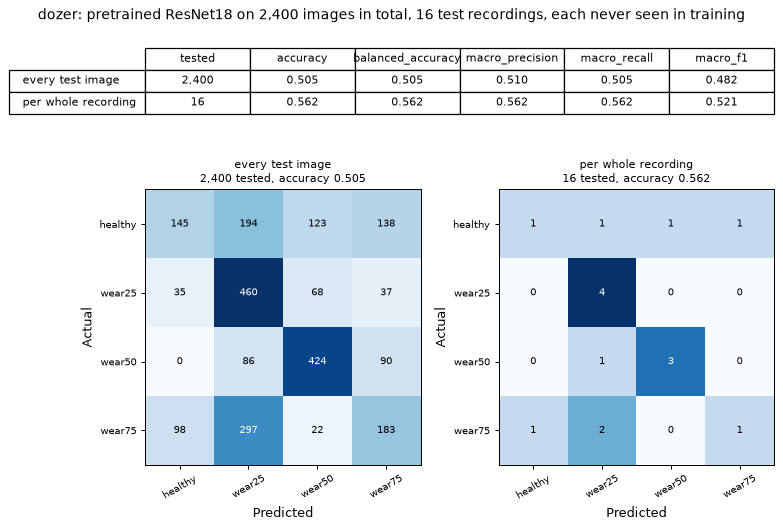

Images per class for each recording appear after rerunning  python Models/dozer.py cnn-pretrained


In [8]:
# The CNN result at three levels: every test image, every 1/10 recording segment, and every whole recording.
# The figure shows the real number of test images; the last table shows how each recording's images were classified.
from notebook_helpers import show_per_recording
show_per_recording("dozer")

## Proposal Week 6: advanced ensemble models (XGBoost / LightGBM)
The same CSV sensor features and the same held-out recordings, now with **XGBoost** and **LightGBM** next to random forest, extra trees and scikit-learn gradient boosting. Settings are fixed in advance; nothing is tuned on the test. `train_seconds` is the total training time.

In [48]:
if all(LOCAL.values()):
    run_script("Models/dozer.py", "ensembles", tail=1)
    run_script("Models/dozer.py", "ensembles", "--split", "time", tail=1)
show_ensembles("dozer")

,accuracy,balanced_accuracy,macro_f1,train_seconds
MAIN | Majority class (control),0.250,0.250,0.100,0.00
MAIN | Random forest,0.375,0.375,0.288,2.10
MAIN | Extra trees,0.438,0.438,0.356,1.26
MAIN | Gradient boosting (scikit-learn),0.438,0.438,0.393,7.57
MAIN | XGBoost,0.438,0.438,0.372,1.77
MAIN | LightGBM,0.562,0.562,0.484,1.75
TIME SPLIT (secondary) | Majority class (control),0.250,0.250,0.100,0.00
TIME SPLIT (secondary) | Random forest,1.000,1.000,1.000,0.48
TIME SPLIT (secondary) | Extra trees,1.000,1.000,1.000,0.30
TIME SPLIT (secondary) | Gradient boosting (scikit-learn),1.000,1.000,1.000,1.75


![Ensemble comparison](../Figures/dozer/dozer_ensembles.png)

## Week 7: anomaly detection (trained on healthy data only)
Isolation Forest and One-Class SVM learn only what **healthy** looks like; anything unusual raises an alarm. No fault labels are used for training. The alarm threshold is set from the healthy training recordings before testing. **ROC-AUC** (1.0 = perfect, 0.5 = guessing) shows how well the score separates healthy from faulty; **fault detection rate** and **false alarm rate** are at that fixed threshold.

In [49]:
if all(LOCAL.values()):
    run_script("Models/dozer.py", "anomaly", tail=1)
    run_script("Models/dozer.py", "anomaly", "--split", "time", tail=1)
show_anomaly("dozer")

,roc_auc,fault_detection_rate,false_alarm_rate,accuracy,test_recordings
MAIN | Isolation Forest,0.6250,0.0000,0.00,0.2500,16.0
MAIN | One-Class SVM,0.5833,0.3333,0.25,0.4375,16.0
TIME SPLIT (secondary) | Isolation Forest,0.9167,0.0000,0.00,0.2500,16.0
TIME SPLIT (secondary) | One-Class SVM,0.7708,0.5000,0.00,0.6250,16.0


![Anomaly scores](../Figures/dozer/dozer_anomaly.png)

Each dot is one test recording; above the dashed line = alarm. Green = healthy, red = faulty.

## Week 7: all available sensor data (every CORA sensor, window and start-up test)
Every 1 s window of vibration X/Y/Z, motor current C1-C3 and temperatures T1-T6, plus the **five start-up tests** per condition and speed, so each held-out speed now has **24 test recordings** (96 in total). Feature set and model are chosen by validation on the training speeds. Temperature identifies the recording session (it separates the conditions already in the first 5 minutes), so temperature sets are shown but never selected. Details: [Week 7 full data](../Documentation/week_07_full_data.md).

In [50]:
run_script("Models/dozer.py", "fulldata", tail=2)   # runs only when ACTIVE_EQUIPMENT = "dozer"
show_fulldata("dozer")

,accuracy (all recordings),test recordings,stationary runs,start-up tests,macro F1
MAIN (unseen speed) | validation-selected,0.5208,96.0,0.6250,0.5000,0.4981
"MAIN | vibration X (as Week 6, all windows) | Random forest",0.4583,96.0,0.5000,0.4500,0.4380
"MAIN | vibration X (as Week 6, all windows) | LightGBM",0.4375,96.0,0.4375,0.4375,0.3988
MAIN | vibration X/Y/Z | Random forest,0.3854,96.0,0.3750,0.3875,0.3799
MAIN | vibration X/Y/Z | LightGBM,0.5417,96.0,0.6250,0.5250,0.5013
MAIN | current C1-C3 | Random forest,0.5208,96.0,0.6250,0.5000,0.5473
MAIN | current C1-C3 | LightGBM,0.5312,96.0,0.5625,0.5250,0.5295
MAIN | vibration + current | Random forest,0.5729,96.0,0.6250,0.5625,0.5812
MAIN | vibration + current | LightGBM,0.5833,96.0,0.6250,0.5750,0.5627
MAIN | vibration + current + temperature pattern (stationary only) | Random forest,0.8750,16.0,0.8750,NaN,0.8611


Validation choices per held-out speed: F5: vibration + current / Random forest; F15: vibration + current / LightGBM; F50: current C1-C3 / Random forest; F60: current C1-C3 / Random forest


![Full-data sensor results](../Figures/dozer/dozer_fulldata.png)

### Week 7: XGBoost / LightGBM and anomaly detection on the full data
Same fair main test (each whole speed held out, 96 test recordings), all vibration and current sensors, settings fixed in advance. Anomaly detectors learn healthy data only; the alarm threshold comes from the training speeds.

In [51]:
run_script("Models/dozer.py", "fulldata", "--part", "ensembles", tail=2)   # runs only when ACTIVE_EQUIPMENT = "dozer"
run_script("Models/dozer.py", "fulldata", "--part", "anomaly", tail=2)
show_fulldata_extras("dozer")

,MAIN accuracy (unseen speed),MAIN macro F1,MAIN stationary,MAIN start-up,TIME SPLIT (secondary),seconds
Majority class (control),0.2500,0.1000,0.2500,0.2500,0.25,0.1
Random forest,0.5729,0.5812,0.6250,0.5625,1.00,4.0
Extra trees,0.5000,0.5051,0.5000,0.5000,1.00,3.0
Gradient boosting (scikit-learn),0.5938,0.5837,0.5625,0.6000,1.00,43.1
XGBoost,0.5312,0.5299,0.4375,0.5500,1.00,6.8
LightGBM,0.5833,0.5627,0.6250,0.5750,1.00,4.7


,roc_auc,fault_detection_rate,false_alarm_rate,test_recordings
MAIN | Isolation Forest,0.6285,0.00,0.00,96.0
TIME SPLIT | Isolation Forest,0.9375,0.00,0.00,16.0
MAIN | One-Class SVM,0.6603,0.25,0.25,96.0
TIME SPLIT | One-Class SVM,0.8333,0.00,0.00,16.0


![Full-data ensembles](../Figures/dozer/dozer_fulldata_ensembles.png)
![Full-data anomaly detection](../Figures/dozer/dozer_fulldata_anomaly.png)

## Try your own CSV
Put the path of any CSV in `CSV_FILE` and run this cell. It can be a **feature table** (same columns as `Processed_Data/dozer_sensor_features_4class.csv`, optional `class` column) or a **raw recording** (one column of CORA Vx vibration values). Set `LABEL` to the true class to see the accuracy. Classes: healthy, wear25, wear50, wear75. The saved model is trained on all project data, so testing on one of the project's own recordings gives an optimistic score; to test fairly, first run `python Models/dozer.py train-final --exclude <recording>`.

In [52]:
CSV_FILE = None   # e.g. r"C:/Users/me/Downloads/my_recording.csv"
LABEL = None      # true class if known
SPEED = None      # raw recordings only: "F5", "F15", "F50" or "F60"
if CSV_FILE:
    run_script("Models/dozer.py", "predict", "--csv", CSV_FILE, *((["--label", LABEL] if LABEL else []) + (["--speed", SPEED] if SPEED else [])), tail=25)
else:
    print("Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).")

Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).


<a id="wheel-loader"></a>
# Wheel Loader (machine 6): electric drive motor — sensor vs camera

| | Sensor | Camera |
|---|---|---|
| Data | CORA vibration (Vx, 3 kHz) | CORA infrared camera |
| Classes | healthy, bearing defect, half-broken rotor bar, broken rotor bar | same four |
| Tested on | 16 runs, one speed held out at a time | the same 16 runs |
| Code | `Models/wheel_loader.py csv` | `Models/wheel_loader.py cnn-pretrained` |

Same CORA laboratory motor/gearbox rig, but **new fault data**: the two rotor-bar faults are CORA conditions no other machine in this project uses (healthy and bearing-defect runs are shared with the Excavator). Large wheel loaders can use electric drive, so the induction motor stands in for the loader's drive motor. Preprocessing uses training data only. Lab data, not a wheel loader; it classifies the present condition, not when to repair.

All of this machine's experiment code is in its `Models/` file; shared notebook set-up is in `notebook_helpers.py`. Run the cells from top to bottom with the **Capstone (.venv)** kernel.

In [53]:
from notebook_helpers import *

LOCAL = setup([
    ("Sensor: CORA vibration (Vx)", "Raw_Data/cora_vibration", "*_Vx.csv", 16),
    ("Camera: CORA infrared, faults", "Raw_Data/cora_drive_faults", "*.mat", 12),
    ("Camera: CORA infrared, healthy", "Raw_Data/cora_gear_wear", "H_*.mat", 4),
])

,environment
git commit,c3b6fcb
python,3.11.9
kernel,project .venv
numpy,2.4.6
scipy,1.17.1
pandas,2.3.3
scikit-learn,1.9.1
opencv-python,4.14.0.94
matplotlib,3.11.2


,location,files,MB,local
data,,,,
Sensor: CORA vibration (Vx),Raw_Data/cora_vibration,36/16,3956.3,True
"Camera: CORA infrared, faults",Raw_Data/cora_drive_faults,20/12,451.3,True
"Camera: CORA infrared, healthy",Raw_Data/cora_gear_wear,4/4,118.2,True


All data is local: running fully offline.


In [54]:
run_script, check = select_equipment(ACTIVE_EQUIPMENT, 'wheel_loader')

## 1. Sensor: vibration (CSV)
Each run's vibration becomes 1-second windows measured in **shaft orders** (multiples of the shaft speed): bearing defects show at higher orders and spikes; broken rotor bars change the motor's slip and the sidebands around the running speed. The features go into a CSV table; the model and feature set are chosen on validation speeds inside the training data, then tested once on the held-out speed.

In [55]:
if all(LOCAL.values()):
    run_script("Models/wheel_loader.py", "csv", tail=2)                    # main: unseen speed
    run_script("Models/wheel_loader.py", "csv", "--split", "time", tail=1)  # secondary: time split
csv_result, time_result = load("wheel_loader_csv_4class.json"), load("wheel_loader_csv_4class_timesplit.json")
show({"MAIN (unseen speed) | Sensor: validation-selected": csv_result["validation_selected"]["score"],
      **{f"MAIN (unseen speed) | Sensor: {k}": v for k, v in csv_result["models"].items()},
      **{f"TIME SPLIT | Sensor: {k}": v for k, v in time_result["models"].items()}})

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
MAIN (unseen speed) | Sensor: validation-selected,0.312,0.312,0.350,0.312,0.325
MAIN (unseen speed) | Sensor: Majority class (control),0.250,0.250,0.062,0.250,0.100
MAIN (unseen speed) | Sensor: Logistic regression,0.312,0.312,0.458,0.312,0.317
MAIN (unseen speed) | Sensor: Random forest,0.250,0.250,0.134,0.250,0.174
TIME SPLIT | Sensor: Majority class (control),0.250,0.250,0.062,0.250,0.100
TIME SPLIT | Sensor: Logistic regression,0.750,0.750,0.792,0.750,0.757
TIME SPLIT | Sensor: Random forest,0.938,0.938,0.950,0.938,0.936


![CSV sensor model](../Figures/wheel_loader/wheel_loader_csv_4class.png) ![Time split](../Figures/wheel_loader/wheel_loader_csv_4class_timesplit.png)

**Two tests, clearly separated.** *Main (unseen speed):* each whole speed is held out, so the model must recognise a fault at a speed it never trained on; CORA has only one run per fault per speed, and every model stays near chance. *Time split (secondary, easier):* the first 60% of every 50-minute run trains, the last 30% tests (10% gap). This asks whether the condition of a machine already seen can be recognised later in time. Because each fault comes from a single recording, part of a high time-split score may come from recognising the recording rather than the fault.

## 2. Camera: infrared images with a pretrained CNN
`export-images` saves all 450 infrared frames per run (7,200 images total, 1,800 per class) as `Images/wheel_loader/<class>/wheel_loader_<class>_<speed>_fNNN.png`. A pretrained ResNet18 was fine-tuned with data augmentation; epochs were chosen on validation recordings. The unseen-speed test holds out entire speeds to prevent adjacent frames from leaking across train and test. The updated full-data result is 3/16 recordings (0.188), below the 0.250 chance baseline; the prior 2,400-image run scored 5/16 (0.312). The secondary time split is 16/16 (1.000), but uses the same recordings in train and test and does not establish new-recording generalization.

In [56]:
if TRAIN_CNN and all(LOCAL.values()):
    run_script("Models/wheel_loader.py", "export-images", tail=1)
    run_script("Models/wheel_loader.py", "cnn-pretrained", tail=1)
    run_script("Models/wheel_loader.py", "cnn-pretrained", "--split", "time", tail=1)
rows = {}
for name, label in (("wheel_loader_cnn_pretrained_4class.json", "MAIN (unseen speed) | Camera: pretrained ResNet18"),
                    ("wheel_loader_cnn_pretrained_4class_timesplit.json", "TIME SPLIT | Camera: pretrained ResNet18")):
    r = load(name)
    if r:
        rows[f"{label} (per run)"] = r["recording_level"]
show(rows)

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
MAIN (unseen speed) | Camera: pretrained ResNet18 (per run),0.188,0.188,0.342,0.188,0.206
TIME SPLIT | Camera: pretrained ResNet18 (per run),1.000,1.000,1.000,1.000,1.000


![Pretrained CNN](../Figures/wheel_loader/wheel_loader_cnn_pretrained_4class.png) ![Time split](../Figures/wheel_loader/wheel_loader_cnn_pretrained_4class_timesplit.png)

**Data (CC BY 4.0):** CORA v2.1, DOI 10.34810/DATA2500 (downloaded in a browser because the repository shows a bot check; every file checked against the publisher MD5 by `python Models/wheel_loader.py intake`).

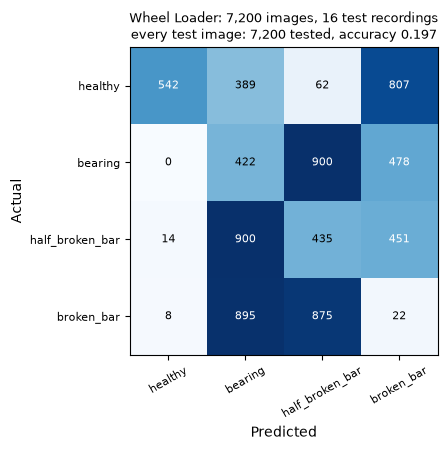

In [7]:
# Every test image of this machine's camera CNN (fair test: the test recordings were never seen in training)
from notebook_helpers import show_test_images
show_test_images("wheel_loader")

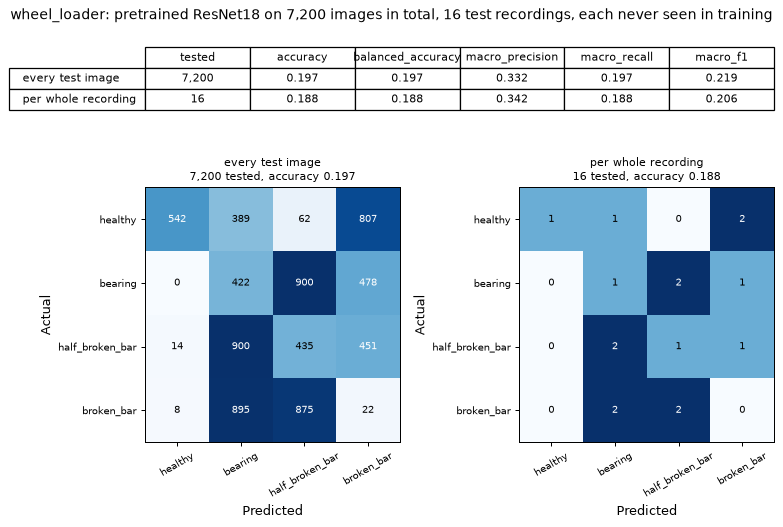

Images per class for each recording appear after rerunning  python Models/wheel_loader.py cnn-pretrained


In [9]:
# The CNN result at three levels: every test image, every 1/10 recording segment, and every whole recording.
# The figure shows the real number of test images; the last table shows how each recording's images were classified.
from notebook_helpers import show_per_recording
show_per_recording("wheel_loader")

## Proposal Week 6: advanced ensemble models (XGBoost / LightGBM)
The same CSV sensor features and the same held-out recordings, now with **XGBoost** and **LightGBM** next to random forest, extra trees and scikit-learn gradient boosting. Settings are fixed in advance; nothing is tuned on the test. `train_seconds` is the total training time.

In [57]:
if all(LOCAL.values()):
    run_script("Models/wheel_loader.py", "ensembles", tail=1)
    run_script("Models/wheel_loader.py", "ensembles", "--split", "time", tail=1)
show_ensembles("wheel_loader")

,accuracy,balanced_accuracy,macro_f1,train_seconds
MAIN | Majority class (control),0.250,0.250,0.100,0.00
MAIN | Random forest,0.250,0.250,0.174,2.37
MAIN | Extra trees,0.250,0.250,0.230,1.40
MAIN | Gradient boosting (scikit-learn),0.250,0.250,0.222,8.69
MAIN | XGBoost,0.250,0.250,0.217,1.85
MAIN | LightGBM,0.250,0.250,0.210,1.66
TIME SPLIT (secondary) | Majority class (control),0.250,0.250,0.100,0.00
TIME SPLIT (secondary) | Random forest,0.938,0.938,0.936,0.74
TIME SPLIT (secondary) | Extra trees,0.938,0.938,0.936,0.45
TIME SPLIT (secondary) | Gradient boosting (scikit-learn),0.938,0.938,0.936,2.49


![Ensemble comparison](../Figures/wheel_loader/wheel_loader_ensembles.png)

## Week 7: anomaly detection (trained on healthy data only)
Isolation Forest and One-Class SVM learn only what **healthy** looks like; anything unusual raises an alarm. No fault labels are used for training. The alarm threshold is set from the healthy training recordings before testing. **ROC-AUC** (1.0 = perfect, 0.5 = guessing) shows how well the score separates healthy from faulty; **fault detection rate** and **false alarm rate** are at that fixed threshold.

In [58]:
if all(LOCAL.values()):
    run_script("Models/wheel_loader.py", "anomaly", tail=1)
    run_script("Models/wheel_loader.py", "anomaly", "--split", "time", tail=1)
show_anomaly("wheel_loader")

,roc_auc,fault_detection_rate,false_alarm_rate,accuracy,test_recordings
MAIN | Isolation Forest,0.3958,0.0000,0.00,0.250,16.0
MAIN | One-Class SVM,0.5000,0.2500,0.25,0.375,16.0
TIME SPLIT (secondary) | Isolation Forest,0.8958,0.0000,0.00,0.250,16.0
TIME SPLIT (secondary) | One-Class SVM,0.6875,0.1667,0.00,0.375,16.0


![Anomaly scores](../Figures/wheel_loader/wheel_loader_anomaly.png)

Each dot is one test recording; above the dashed line = alarm. Green = healthy, red = faulty.

## Week 7: all available sensor data (every CORA sensor, window and start-up test)
Every 1 s window of vibration X/Y/Z, motor current C1-C3 and temperatures T1-T6, plus the **five start-up tests** per condition and speed, so each held-out speed now has **24 test recordings** (96 in total). Feature set and model are chosen by validation on the training speeds. Temperature identifies the recording session (it separates the conditions already in the first 5 minutes), so temperature sets are shown but never selected. Details: [Week 7 full data](../Documentation/week_07_full_data.md).

In [59]:
run_script("Models/wheel_loader.py", "fulldata", tail=2)   # runs only when ACTIVE_EQUIPMENT = "wheel_loader"
show_fulldata("wheel_loader")

,accuracy (all recordings),test recordings,stationary runs,start-up tests,macro F1
MAIN (unseen speed) | validation-selected,0.4062,96.0,0.5000,0.3875,0.3445
"MAIN | vibration X (as Week 6, all windows) | Random forest",0.3229,96.0,0.2500,0.3375,0.3276
"MAIN | vibration X (as Week 6, all windows) | LightGBM",0.2604,96.0,0.2500,0.2625,0.2469
MAIN | vibration X/Y/Z | Random forest,0.3229,96.0,0.2500,0.3375,0.2945
MAIN | vibration X/Y/Z | LightGBM,0.3125,96.0,0.2500,0.3250,0.2271
MAIN | current C1-C3 | Random forest,0.3229,96.0,0.3750,0.3125,0.2207
MAIN | current C1-C3 | LightGBM,0.4062,96.0,0.5000,0.3875,0.3445
MAIN | vibration + current | Random forest,0.3333,96.0,0.5000,0.3000,0.3322
MAIN | vibration + current | LightGBM,0.3854,96.0,0.4375,0.3750,0.4028
MAIN | vibration + current + temperature pattern (stationary only) | Random forest,0.8125,16.0,0.8125,NaN,0.8128


Validation choices per held-out speed: F5: current C1-C3 / LightGBM; F15: current C1-C3 / Random forest; F50: current C1-C3 / LightGBM; F60: current C1-C3 / LightGBM


![Full-data sensor results](../Figures/wheel_loader/wheel_loader_fulldata.png)

### Week 7: XGBoost / LightGBM and anomaly detection on the full data
Same fair main test (each whole speed held out, 96 test recordings), all vibration and current sensors, settings fixed in advance. Anomaly detectors learn healthy data only; the alarm threshold comes from the training speeds.

In [60]:
run_script("Models/wheel_loader.py", "fulldata", "--part", "ensembles", tail=2)   # runs only when ACTIVE_EQUIPMENT = "wheel_loader"
run_script("Models/wheel_loader.py", "fulldata", "--part", "anomaly", tail=2)
show_fulldata_extras("wheel_loader")

,MAIN accuracy (unseen speed),MAIN macro F1,MAIN stationary,MAIN start-up,TIME SPLIT (secondary),seconds
Majority class (control),0.2500,0.1000,0.2500,0.2500,0.2500,0.1
Random forest,0.3333,0.3326,0.5000,0.3000,1.0000,4.0
Extra trees,0.3229,0.2891,0.3125,0.3250,1.0000,2.8
Gradient boosting (scikit-learn),0.3229,0.2867,0.3125,0.3250,1.0000,32.4
XGBoost,0.2917,0.2781,0.2500,0.3000,0.9375,5.9
LightGBM,0.3646,0.3787,0.3750,0.3625,1.0000,4.4


,roc_auc,fault_detection_rate,false_alarm_rate,test_recordings
MAIN | Isolation Forest,0.5336,0.00,0.00,96.0
TIME SPLIT | Isolation Forest,0.7500,0.00,0.00,16.0
MAIN | One-Class SVM,0.5891,0.25,0.25,96.0
TIME SPLIT | One-Class SVM,0.6042,0.00,0.00,16.0


![Full-data ensembles](../Figures/wheel_loader/wheel_loader_fulldata_ensembles.png)
![Full-data anomaly detection](../Figures/wheel_loader/wheel_loader_fulldata_anomaly.png)

## Try your own CSV
Put the path of any CSV in `CSV_FILE` and run this cell. It can be a **feature table** (same columns as `Processed_Data/wheel_loader_sensor_features_4class.csv`, optional `class` column) or a **raw recording** (one column of sensor values). Set `LABEL` to the true class to see the accuracy. Classes: healthy, bearing, half_broken_bar, broken_bar. The saved model is trained on all project data, so testing on one of the project's own recordings gives an optimistic score; to test fairly, first run `python Models/wheel_loader.py train-final --exclude <recording>`.

In [61]:
CSV_FILE = None   # e.g. r"C:/Users/me/Downloads/my_recording.csv"
LABEL = None      # true class if known
SPEED = None      # raw recordings only: "F5", "F15", "F50" or "F60"
if CSV_FILE:
    run_script("Models/wheel_loader.py", "predict", "--csv", CSV_FILE, *((["--label", LABEL] if LABEL else []) + (["--speed", SPEED] if SPEED else [])), tail=25)
else:
    print("Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).")

Set CSV_FILE to a CSV path to get predictions (and accuracy if LABEL is set).


<a id="future-equipment"></a>
# Future equipment: Drill Rig and Grader

These two categories remain mapped but **not experimentally evaluated**. When a genuine sensor-plus-image experiment is complete, append its code, outputs, figures, classes, and limitations **here**, then update the summary table above. Do not copy a different machine's score and call it an independent test.